# CS5785 Midterm — Part 2: Predicting clinical-trial outcomes per phase, and analysing errors by stopping reason

**Task.** Predict whether a trial met its primary endpoint (label = 1), separately for Phase I, II and III. Train on
`outcome_train.csv` (8,037 rows), select on `outcome_val.csv` (1,013 rows), submit P(label = 1) for `outcome_test.csv`
(1,500 rows, 500 per phase, start years 2013–2022). Kaggle metric: log loss (mean over phases). Then analyse the validation
errors by Part 1 stopping reason and use that analysis to improve the classifier.

**Notebook map**
0. Setup & data
1. Method library (features + models; every experiment below uses it)
2. EDA: label rate by phase and start year, the Part 1 overlap (and why it is a leakage trap)
3. Feature blocks (built once per fold and cached)
4. Exp A: baseline classifiers (Multinomial NB, logistic regression, kNN; unigram vs bigram; per-phase vs pooled)
5. Exp B: error analysis of the original model by stopping reason
6. Exp C: targeted features (eligibility design, historical drug/disease outcomes, Tanimoto drug neighbours, K-Means clusters) and ablation
7. Exp D: gradient boosting, stacking ensemble and calibration (+ cross-fitted CV of the stack); Exp D2: Phase III-targeted attempts
8. Exp E: time shift (adversarial validation; temporal holdout to choose how to extrapolate the start-year trend)
9. Final: original vs improved model (overall metrics, paired bootstrap, per-reason error rates, threshold trade-off), Kaggle submission
10. Results summary

Reason embeddings and reason labels are used **only** in the error analysis (Sections 5 and 9), never as model inputs.
No deep learning is used. Runs top to bottom on a laptop CPU in roughly 10 minutes.

## 0. Setup & data

In [1]:
import sys, os, subprocess, glob, zipfile, time
IN_COLAB = 'google.colab' in sys.modules
try:
    import rdkit
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rdkit'], check=True)

DATA_DIR = os.environ.get('P2_DATA_DIR', './data/')
if not os.path.exists(os.path.join(DATA_DIR, 'outcome_train.csv')):
    zips = glob.glob('*.zip')
    if not zips and IN_COLAB:
        from google.colab import files
        print('Upload the Part 2 Kaggle zip (outcome_*.csv)'); files.upload(); zips = glob.glob('*.zip')
    os.makedirs(DATA_DIR, exist_ok=True)
    for z in zips: zipfile.ZipFile(z).extractall(DATA_DIR)
# Part 1 handoff (reason labels for all 1,561 Part 1 trials; produced by part1.ipynb)
P1_LABELS = 'outputs/part1_reason_labels_all_trials.csv'
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True)
print(sorted(os.listdir(DATA_DIR)), os.path.exists(P1_LABELS))

['outcome_test.csv', 'outcome_train.csv', 'outcome_val.csv'] True


In [2]:
import matplotlib.pyplot as plt, matplotlib as mpl
# Same palette / style as part1.ipynb (validated colorblind-safe categorical order; grays for context).
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID, GRAY = '#0b0b0b', '#52514e', '#e4e3df', '#b8b7b0'
PH_COL = {'I': BLUE, 'II': ORANGE, 'III': AQUA}
mpl.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.titlecolor': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True, 'font.size': 9.5, 'legend.frameon': False,
    'lines.linewidth': 2})
SEED = 0

## 1. Method library
Feature extraction (text, eligibility structure, RDKit chemistry, historical outcome encodings, Tanimoto neighbours) and
metrics. Label-derived features are always computed **out-of-fold** on the rows they are used to train on, grouped by
`trial_id` so a multi-phase trial never sees its own label.

In [3]:
import ast, re, warnings
import numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, log_loss

warnings.filterwarnings('ignore')
PHASES = ['I', 'II', 'III']
REASONS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']


# ----------------------------------------------------------------------------- parsing
def _lit(s):
    if pd.isna(s) or s == '':
        return []
    try:
        v = ast.literal_eval(s)
        return list(v) if isinstance(v, (list, tuple)) else [v]
    except Exception:
        return [s]


def parse_icd(s):
    out = []
    for chunk in _lit(s):
        out += [c for c in _lit(chunk) if isinstance(c, str)]
    return out


def split_semi(s):
    return [] if pd.isna(s) or s == '' else [x.strip() for x in str(s).split(';') if x.strip()]


def parse(df):
    df = df.copy()
    df['dis_list'] = df.diseases_cleaned.map(lambda s: [str(x).lower() for x in _lit(s)])
    df['drug_list'] = df.drugs.map(lambda s: [str(x).lower() for x in _lit(s)])
    df['icd_list'] = df.icdcodes.map(parse_icd)
    df['icd3'] = df.icd_list.map(lambda L: sorted({c.split('.')[0] for c in L}))
    df['icd_ch'] = df.icd_list.map(lambda L: sorted({c[0] for c in L if c}))
    for c in ['matched_drugs', 'drug_targets', 'drug_actions', 'drug_pathways', 'drug_smiles']:
        df[c + '_l'] = df[c].map(split_semi)
    df['criteria'] = df.criteria.fillna('')
    df['year'] = df.start_year.fillna(df.start_year.median())
    return df


# ----------------------------------------------------------------------------- criteria structure
_num = re.compile(r'(?:≥|≤|>=|<=|>|<|\bULN\b|x\s*ULN|mg/dl|g/dl|/mm3|/ul|ml/min)', re.I)
_age = re.compile(r'(\d{1,2})\s*(?:years|yrs|year)', re.I)


def criteria_struct(text):
    t = text or ''
    low = t.lower()
    k = low.find('exclusion criteria')
    inc, exc = (t[:k], t[k:]) if k >= 0 else (t, '')
    bullets = lambda s: len(re.findall(r'\n\s*(?:-|\d+\.|•|\*)\s+', s))
    ages = [int(a) for a in _age.findall(t)]
    return dict(
        crit_len=np.log1p(len(t)), n_inc=bullets(inc), n_exc=bullets(exc),
        exc_inc_ratio=np.log1p(bullets(exc)) - np.log1p(bullets(inc)),
        n_lab_thresholds=len(_num.findall(t)),
        age_min=min(ages) if ages else -1, age_max=max(ages) if ages else -1,
        age_span=(max(ages) - min(ages)) if len(ages) > 1 else -1,
        healthy_vol=int('healthy' in low), pediatric=int(bool(re.search(r'child|pediatric|infant|adolescent', low))),
        prior_tx_failure=int(bool(re.search(r'refractory|relapsed|failed|progress(ed|ion) (on|after)', low))),
        metastatic=int('metasta' in low), pregnancy=int('pregnan' in low),
        ecog=int(bool(re.search(r'ecog|karnofsky|performance status', low))),
        life_exp=int('life expectancy' in low),
    )


def design_features(df):
    S = pd.DataFrame([criteria_struct(t) for t in df.criteria], index=df.index)
    S['n_drugs'] = df.drug_list.map(len)
    S['n_dis'] = df.dis_list.map(len)
    S['n_icd'] = df.icd_list.map(len)
    S['placebo'] = df.drug_list.map(lambda L: int(any('placebo' in d for d in L)))
    S['combo'] = df.drug_list.map(lambda L: int(any(re.search(r'\band\b|\bplus\b|\+|/', d) for d in L)))
    S['has_match'] = (df.matched_drugs_l.map(len) > 0).astype(int)
    S['n_matched'] = df.matched_drugs_l.map(len)
    S['n_targets'] = np.log1p(df.drug_targets_l.map(len))
    S['n_pathways'] = np.log1p(df.drug_pathways_l.map(len))
    S['multi_phase'] = df.phase_detail.str.contains('/').astype(int)
    S['oncology'] = df.icd_ch.map(lambda L: int('C' in L))
    return S


# ----------------------------------------------------------------------------- text
def text_fields(df):
    dis = df.dis_list.map(' '.join)
    drg = df.drug_list.map(' '.join)
    icd = df.apply(lambda r: ' '.join(['ICD_' + c for c in r.icd3] + ['CH_' + c for c in r.icd_ch]), axis=1)
    return dis, drg, icd


class TextBlock:
    """TF-IDF (or raw counts for Naive Bayes) on criteria + disease + drug + ICD tokens."""

    def __init__(self, ngram=(1, 2), counts=False, min_df=5, max_feat=40000):
        V = CountVectorizer if counts else TfidfVectorizer
        kw = {} if counts else dict(sublinear_tf=True)
        self.v = [V(ngram_range=ngram, min_df=min_df, max_features=max_feat, stop_words='english', **kw),
                  V(ngram_range=(1, 2), min_df=3, **kw),
                  V(ngram_range=(1, 1), min_df=3, **kw),
                  V(token_pattern=r'\S+', lowercase=False, min_df=3, **kw)]

    def _cols(self, df):
        return [df.criteria] + list(text_fields(df))

    def fit(self, df):
        for v, c in zip(self.v, self._cols(df)):
            v.fit(c)
        return self

    def transform(self, df, blocks=(0, 1, 2, 3)):
        return sp.hstack([self.v[i].transform(c) for i, c in enumerate(self._cols(df)) if i in blocks]).tocsr()


# ----------------------------------------------------------------------------- drugs / RDKit
_FP_CACHE = {}


def _mol_feats(smi):
    if smi in _FP_CACHE:
        return _FP_CACHE[smi]
    from rdkit import Chem, RDLogger
    from rdkit.Chem import Descriptors, rdFingerprintGenerator, QED
    RDLogger.DisableLog('rdApp.*')
    m = Chem.MolFromSmiles(smi)
    if m is None:
        _FP_CACHE[smi] = None
        return None
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
    fp = gen.GetFingerprintAsNumPy(m).astype(np.uint8)
    try:
        q = QED.qed(m)
    except Exception:
        q = np.nan
    d = np.array([Descriptors.MolWt(m), Descriptors.MolLogP(m), Descriptors.TPSA(m), Descriptors.NumHDonors(m),
                  Descriptors.NumHAcceptors(m), Descriptors.NumRotatableBonds(m), Descriptors.RingCount(m), q])
    _FP_CACHE[smi] = (fp, d)
    return _FP_CACHE[smi]


DESC_NAMES = ['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'RotB', 'Rings', 'QED']


def drug_chem(df):
    """Per trial: element-wise max Morgan fingerprint (zeros if no matched drug) and mean descriptors
    (NaN -> filled with train median later; a has_match flag carries the missingness)."""
    FP = np.zeros((len(df), 1024), np.uint8)
    DS = np.full((len(df), len(DESC_NAMES)), np.nan)
    for i, L in enumerate(df.drug_smiles_l):
        res = [r for r in (_mol_feats(s) for s in L) if r is not None]
        if res:
            FP[i] = np.max([r[0] for r in res], 0)
            DS[i] = np.nanmean([r[1] for r in res], 0)
    return FP, pd.DataFrame(DS, columns=DESC_NAMES, index=df.index)


class MultiHot:
    def __init__(self, col, min_count=20, prefix=''):
        self.col, self.min_count, self.prefix = col, min_count, prefix

    def fit(self, df):
        from collections import Counter
        c = Counter(x for L in df[self.col] for x in set(L))
        self.vocab = sorted(k for k, v in c.items() if v >= self.min_count)
        self.idx = {k: i for i, k in enumerate(self.vocab)}
        return self

    def transform(self, df):
        rows, cols = [], []
        for r, L in enumerate(df[self.col]):
            for x in set(L):
                if x in self.idx:
                    rows.append(r); cols.append(self.idx[x])
        return sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(df), len(self.vocab)))

    @property
    def names(self):
        return [self.prefix + v for v in self.vocab]


# ----------------------------------------------------------------------------- historical outcome encodings (HINT-style)
ENC_KEYS = {'drug': 'drug_list', 'disease': 'dis_list', 'icd3': 'icd3', 'target': 'drug_targets_l'}


def _phase_resid(df):
    pm = df.groupby('phase').label.mean()
    return df.label - df.phase.map(pm)


def _key_table(df, col):
    r = _phase_resid(df)
    rows = [(k, v) for L, v in zip(df[col], r) for k in set(L)]
    if not rows:
        return pd.DataFrame(columns=['s', 'n'])
    t = pd.DataFrame(rows, columns=['k', 'r']).groupby('k').r.agg(['sum', 'count'])
    t.columns = ['s', 'n']
    return t


def _apply_table(t, L, m):
    vals, cnt = [], 0
    for k in L:
        if k in t.index:
            s, n = t.loc[k, 's'], t.loc[k, 'n']
            vals.append(s / (n + m)); cnt += n
    if not vals:
        return [0.0, 0.0, 0.0, 0.0]
    return [np.mean(vals), np.min(vals), np.max(vals), np.log1p(cnt)]


def history_encode(fit_df, apply_df, m=10):
    """Smoothed success-rate residual (vs phase prior) of each drug / disease / ICD3 / target, pooled over phases,
    aggregated per trial as mean/min/max + log(#prior trials). Shrinkage m pulls rare keys toward 0."""
    out = {}
    for name, col in ENC_KEYS.items():
        t = _key_table(fit_df, col)
        A = np.array([_apply_table(t, L, m) for L in apply_df[col]])
        for j, s in enumerate(['mean', 'min', 'max', 'logn']):
            out[f'h_{name}_{s}'] = A[:, j]
    return pd.DataFrame(out, index=apply_df.index)


def history_encode_oof(df, n_splits=5, m=10, seed=0):
    """Out-of-fold version for the training set, grouped by trial_id so a multi-phase trial never encodes itself."""
    res = pd.DataFrame(index=df.index)
    parts = []
    for tr_i, te_i in GroupKFold(n_splits).split(df, groups=df.trial_id):
        parts.append(history_encode(df.iloc[tr_i], df.iloc[te_i], m))
    return pd.concat(parts).loc[df.index]


# ----------------------------------------------------------------------------- Tanimoto kNN on drug structure
def tanimoto(A, B):
    A = A.astype(np.float32); B = B.astype(np.float32)
    inter = A @ B.T
    na, nb = A.sum(1)[:, None], B.sum(1)[None, :]
    return inter / np.maximum(na + nb - inter, 1)


def tanimoto_knn(FP_fit, y_fit, phase_fit, FP_app, phase_app, k=10, exclude_self_groups=None, groups_fit=None):
    """For each trial with a matched drug: similarity-weighted mean phase-residual outcome of its k most
    structurally similar training trials, plus the top similarity. Zeros for trials without drugs."""
    has_f = FP_fit.sum(1) > 0
    has_a = FP_app.sum(1) > 0
    pm = pd.Series(y_fit).groupby(phase_fit).mean()
    r = y_fit - pd.Series(phase_fit).map(pm).values
    out = np.zeros((len(FP_app), 2))
    if has_a.sum() == 0:
        return out
    S = tanimoto(FP_app[has_a], FP_fit[has_f])
    if exclude_self_groups is not None:
        ga = exclude_self_groups[has_a][:, None]; gf = groups_fit[has_f][None, :]
        S[ga == gf] = -1
    rf = r[has_f]
    idx = np.argsort(-S, 1)[:, :k]
    sv = np.take_along_axis(S, idx, 1).clip(0)
    out[has_a, 0] = (sv * rf[idx]).sum(1) / np.maximum(sv.sum(1), 1e-6)
    out[has_a, 1] = sv[:, 0]
    return out


# ----------------------------------------------------------------------------- metrics
def metrics(y, p, t=0.5):
    y = np.asarray(y); p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return dict(F1=f1_score(y, p >= t), ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                LogLoss=log_loss(y, p), n=len(y))


def phase_table(df, p, t=0.5, name=''):
    rows = []
    for ph in PHASES:
        m = (df.phase == ph).values
        rows.append(dict(model=name, phase=ph, **metrics(df.label.values[m], p[m], t)))
    out = pd.DataFrame(rows)
    return out


def summarize(df, p, name, t=0.5):
    tab = phase_table(df, p, t, name)
    s = tab[['F1', 'ROC_AUC', 'PR_AUC', 'LogLoss']].mean()
    return tab, dict(model=name, **{f'{k}_mean': v for k, v in s.items()})

## 2. EDA

In [4]:
train = parse(pd.read_csv(DATA_DIR + 'outcome_train.csv'))
val = parse(pd.read_csv(DATA_DIR + 'outcome_val.csv'))
test = parse(pd.read_csv(DATA_DIR + 'outcome_test.csv'))
p1 = pd.read_csv(P1_LABELS).set_index('ID')
for n, d in [('train', train), ('val', val), ('test', test)]:
    s = d.groupby('phase').label.agg(['size', 'mean']).round(3) if 'label' in d else d.groupby('phase').size()
    print(n, len(d), 'years', int(d.start_year.min()), '-', int(d.start_year.max()), '\n', s, '\n')
print('Drug matched (train / test):', round(train.matched_drugs.notna().mean(), 3), round(test.matched_drugs.notna().mean(), 3))
print('phase_detail in test:', test.phase_detail.value_counts().to_dict())

train 8037 years 1993 - 2013 
        size   mean
phase             
I      1012  0.566
II     3950  0.477
III    3075  0.653 

val 1013 years 1995 - 2013 
        size   mean
phase             
I       149  0.570
II      501  0.471
III     363  0.661 

test 1500 years 2014 - 2021 
 phase
I      500
II     500
III    500
dtype: int64 

Drug matched (train / test): 0.457 0.393
phase_detail in test: {'phase 3': 468, 'phase 2': 413, 'phase 1': 340, 'phase 1/phase 2': 203, 'phase 2/phase 3': 53, 'early phase 1': 23}


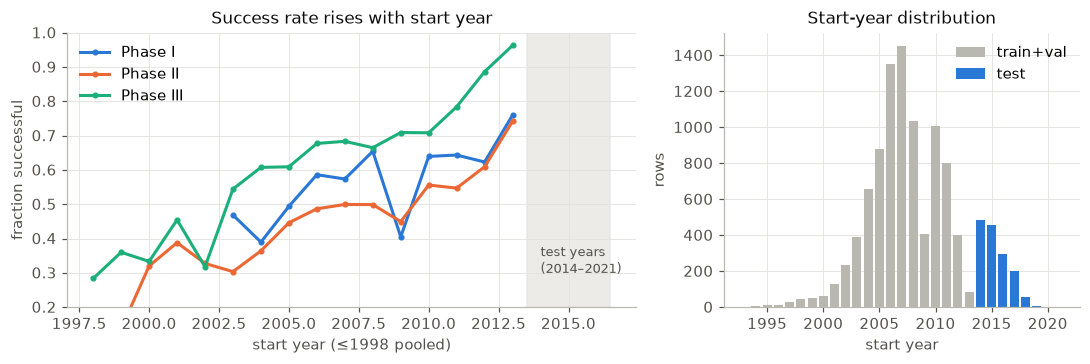

In [5]:
# Success rate by start year and phase: a strong upward trend, and the test years lie entirely beyond the training range.
tv = pd.concat([train, val], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={'width_ratios': [1.6, 1]})
for ph in PHASES:
    g = tv[tv.phase == ph].groupby(tv.year.clip(1998, 2013)).label.agg(['mean', 'size'])
    g = g[g['size'] >= 15]
    ax[0].plot(g.index, g['mean'], marker='o', ms=3, color=PH_COL[ph], label=f'Phase {ph}')
ax[0].axvspan(2013.5, 2016.5, color=GRID, alpha=.7); ax[0].text(2014, .3, 'test years\n(2014–2021)', color=INK2, fontsize=8.5)
ax[0].set(xlabel='start year (≤1998 pooled)', ylabel='fraction successful', title='Success rate rises with start year', ylim=(.2, 1))
ax[0].legend(loc='upper left')
yr = pd.DataFrame({'train+val': tv.year.value_counts(), 'test': test.year.value_counts()}).fillna(0).sort_index()
ax[1].bar(yr.index, yr['train+val'], color=GRAY, label='train+val'); ax[1].bar(yr.index, yr['test'], color=BLUE, label='test')
ax[1].set(xlabel='start year', ylabel='rows', title='Start-year distribution'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/p2_fig1_success_by_year.png', bbox_inches='tight'); plt.show()

In [6]:
# The Part 1 overlap. Every Part 1 trial stopped early, so it almost always failed. 19% of training rows are Part 1 trials,
# but by construction NO test trial is in Part 1. A "trial is in Part 1" flag is a near-perfect predictor on train/val and
# useless on test: classic leakage, so we never use it (it is shown here only to quantify the trap).
for n, d in [('train', train), ('val', val), ('test', test)]:
    m = d.trial_id.isin(p1.index)
    print(f'{n:5s}: {m.sum():5d} rows in Part 1' + (f'; label mean of those = {d[m].label.mean():.3f} vs {d[~m].label.mean():.3f} otherwise' if 'label' in d else ''))

train:  1504 rows in Part 1; label mean of those = 0.001 vs 0.683 otherwise
val  :   198 rows in Part 1; label mean of those = 0.000 vs 0.688 otherwise
test :     0 rows in Part 1


## 3. Feature blocks
`build_blocks(fit_df, app_df)` fits every transformer on `fit_df` only and returns feature blocks for both.
Blocks:
* `tfidf`: TF-IDF of eligibility criteria (1–2-grams), disease names, drug names, ICD-3 codes + chapters
* `tfidf_uni`: same, unigrams only; `counts`: raw unigram counts (bag of words, for Multinomial NB)
* `design`: hand-built eligibility / design features (number of inclusion & exclusion criteria, lab thresholds, age range,
  refractory/metastatic/healthy-volunteer flags, number of drugs, placebo, combination therapy, has-matched-drug...)
* `desc`: mean RDKit descriptors of matched drugs (MolWt, LogP, TPSA, HBD, HBA, rotatable bonds, rings, QED)
* `fp`: max Morgan fingerprint (1024 bits); `act` / `path`: multi-hot drug actions / Reactome pathways
* `hist`: HINT-style historical outcome encodings: smoothed success-rate residual (vs phase prior) of each drug, disease,
  ICD-3 code and protein target among *other* training trials, aggregated per trial (mean/min/max/log count)
* `tani`: Tanimoto kNN: similarity-weighted outcome residual of the 10 structurally most similar training trials
* `clrate_k`: K-Means (k ∈ {10, 25, 50}) on the L2-normalised 100-d SVD of criteria TF-IDF; smoothed outcome residual of the trial's cluster

In [7]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans

KS = (10, 25, 50)


def _cluster_rate(labels_fit, y_fit, phase_fit, labels_app, m=20):
    pm = pd.Series(y_fit).groupby(phase_fit).mean()
    r = pd.Series(y_fit - pd.Series(phase_fit).map(pm).values)
    g = r.groupby(labels_fit).agg(['sum', 'count'])
    rate = g['sum'] / (g['count'] + m)
    return pd.Series(labels_app).map(rate).fillna(0).values


def build_blocks(fit, app, seed=SEED):
    t0 = time.time()
    fit = fit.reset_index(drop=True); app = app.reset_index(drop=True)
    tb = TextBlock(ngram=(1, 2)).fit(fit); tbu = TextBlock(ngram=(1, 1)).fit(fit); tbc = TextBlock(ngram=(1, 1), counts=True).fit(fit)
    acts = MultiHot('drug_actions_l', 20).fit(fit); paths = MultiHot('drug_pathways_l', 30).fit(fit)
    FPf, DSf = drug_chem(fit); FPa, DSa = drug_chem(app); med = DSf.median()
    crit_f = tb.transform(fit, blocks=(0,)); crit_a = tb.transform(app, blocks=(0,))
    svd = TruncatedSVD(100, random_state=seed).fit(crit_f)
    Zf, Za = normalize(svd.transform(crit_f)), normalize(svd.transform(crit_a))
    kms = {k: KMeans(k, n_init=4, random_state=seed).fit(Zf) for k in KS}

    def common(df, FP, DS, Z):
        return dict(tfidf=tb.transform(df), tfidf_uni=tbu.transform(df), counts=tbc.transform(df),
                    design=design_features(df).reset_index(drop=True), desc=DS.fillna(med).reset_index(drop=True),
                    fp=sp.csr_matrix(FP.astype(np.float32)), act=acts.transform(df), path=paths.transform(df),
                    phase=pd.get_dummies(df.phase).reindex(columns=PHASES, fill_value=0).astype(float).values,
                    year=df.year.values, svd=Z, **{f'cl_{k}': kms[k].predict(Z) for k in KS})
    Bf, Ba = common(fit, FPf, DSf, Zf), common(app, FPa, DSa, Za)
    y, ph, grp = fit.label.values, fit.phase.values, fit.trial_id.values
    # label-derived blocks: out-of-fold on fit, full-fit on app
    Bf['hist'] = history_encode_oof(fit).reset_index(drop=True)
    Ba['hist'] = history_encode(fit, app).reset_index(drop=True)
    Bf['tani'] = np.zeros((len(fit), 2))
    for k in KS: Bf[f'clrate_{k}'] = np.zeros(len(fit))
    for a, b in GroupKFold(5).split(fit, groups=grp):
        Bf['tani'][b] = tanimoto_knn(FPf[a], y[a], ph[a], FPf[b], ph[b])
        for k in KS: Bf[f'clrate_{k}'][b] = _cluster_rate(Bf[f'cl_{k}'][a], y[a], ph[a], Bf[f'cl_{k}'][b])
    Ba['tani'] = tanimoto_knn(FPf, y, ph, FPa, app.phase.values)
    for k in KS: Ba[f'clrate_{k}'] = _cluster_rate(Bf[f'cl_{k}'], y, ph, Ba[f'cl_{k}'])
    Bf['_t'] = time.time() - t0
    return Bf, Ba


DENSE_NAMES = {}
def dense(B, blocks):
    parts, names = [], []
    for b in blocks:
        v = B[b]
        if isinstance(v, pd.DataFrame): names += list(v.columns); v = v.values
        elif sp.issparse(v): v = v.toarray(); names += [f'{b}_{i}' for i in range(v.shape[1])]
        else:
            v = np.asarray(v, float); v = v[:, None] if v.ndim == 1 else v
            names += [b] if v.shape[1] == 1 else ([f'ph_{p}' for p in PHASES] if b == 'phase' else [f'{b}_{i}' for i in range(v.shape[1])])
        parts.append(v)
    DENSE_NAMES[tuple(blocks)] = names
    return np.hstack(parts)


# Validation blocks (fit on train, applied to val) and 5 grouped CV folds on train, all cached.
t0 = time.time()
BT, BV = build_blocks(train, val)
FOLDS = []
for a, b in GroupKFold(5).split(train, groups=train.trial_id):
    fa, fb = train.iloc[a].reset_index(drop=True), train.iloc[b].reset_index(drop=True)
    FOLDS.append((a, b, fa, fb) + build_blocks(fa, fb))
print(f'blocks built in {time.time() - t0:.0f}s; tfidf dims = {BT["tfidf"].shape[1]}, design = {BT["design"].shape[1]}, '
      f'fp = 1024, act = {BT["act"].shape[1]}, path = {BT["path"].shape[1]}, hist = {BT["hist"].shape[1]}')

blocks built in 97s; tfidf dims = 44388, design = 26, fp = 1024, act = 17, path = 1195, hist = 16


### Model zoo and evaluation harness
A model is `f(B_fit, fit_df, B_app, app_df) -> P(label = 1)`. `evaluate` reports validation metrics per phase (F1 at 0.5,
ROC-AUC, PR-AUC, log loss) **and** the 5-fold grouped-CV mean ± sd on train (more stable: val has only 149 Phase I rows).

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier


def per_phase(make, block):
    def f(Bf, fit, Ba, app):
        p = np.zeros(len(app))
        for ph in PHASES:
            a, b = (fit.phase == ph).values, (app.phase == ph).values
            X = Bf[block]; Xa = Ba[block]
            p[b] = make().fit(X[a], fit.label.values[a]).predict_proba(Xa[b])[:, 1]
        return p
    return f


def lr_pooled(C=0.3, sparse_blocks=('tfidf',), dense_blocks=('phase',)):
    def f(Bf, fit, Ba, app):
        sc = StandardScaler().fit(dense(Bf, dense_blocks))
        X = sp.hstack([Bf[s] for s in sparse_blocks] + [sp.csr_matrix(sc.transform(dense(Bf, dense_blocks)))]).tocsr()
        Xa = sp.hstack([Ba[s] for s in sparse_blocks] + [sp.csr_matrix(sc.transform(dense(Ba, dense_blocks)))]).tocsr()
        return LogisticRegression(C=C, max_iter=5000).fit(X, fit.label).predict_proba(Xa)[:, 1]
    return f


HGB_KW = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED)
def hgb(blocks, **kw):
    def f(Bf, fit, Ba, app):
        m = HistGradientBoostingClassifier(**{**HGB_KW, **kw}).fit(dense(Bf, blocks), fit.label)
        return m.predict_proba(dense(Ba, blocks))[:, 1]
    return f


RESULTS, PHASE_ROWS, OOF, VALP = [], [], {}, {}
def evaluate(name, f, cv=True, group='', verbose=True):
    p = f(BT, train, BV, val); VALP[name] = p
    tab, s = summarize(val, p, name)
    row = dict(group=group, **s)
    if cv:
        oof = np.zeros(len(train)); fold_auc, fold_ll = [], []
        for a, b, fa, fb, Bf, Ba in FOLDS:
            oof[b] = f(Bf, fa, Ba, fb)
            t, _ = summarize(fb, oof[b], name); fold_auc.append(t.ROC_AUC.mean()); fold_ll.append(t.LogLoss.mean())
        OOF[name] = oof
        row.update(cv_auc=np.mean(fold_auc), cv_auc_sd=np.std(fold_auc), cv_ll=np.mean(fold_ll), cv_ll_sd=np.std(fold_ll))
    RESULTS.append(row); PHASE_ROWS.append(tab.assign(group=group))
    if verbose:
        print(f"{name:45s} val AUC {s['ROC_AUC_mean']:.3f}  PR {s['PR_AUC_mean']:.3f}  F1 {s['F1_mean']:.3f}  LL {s['LogLoss_mean']:.3f}"
              + (f"  | CV AUC {row['cv_auc']:.3f}±{row['cv_auc_sd']:.3f}  LL {row['cv_ll']:.3f}" if cv else ''))
    return p


def res_table(group=None):
    d = pd.DataFrame(RESULTS)
    return (d if group is None else d[d.group == group]).drop(columns='group').round(3)

## 4. Exp A: baseline classifiers
Text-only models, one model per phase unless stated otherwise. Hyperparameters swept: LR `C`, NB `alpha`, kNN `k`.

In [9]:
for C in [0.1, 0.3, 1, 3]:
    evaluate(f'LR per-phase, TF-IDF 1-2g, C={C}', per_phase(lambda C=C: LogisticRegression(C=C, max_iter=5000), 'tfidf'), group='A')
evaluate('LR per-phase, TF-IDF unigram, C=0.3', per_phase(lambda: LogisticRegression(C=0.3, max_iter=5000), 'tfidf_uni'), group='A')
for a in [0.1, 1.0]:
    evaluate(f'Multinomial NB per-phase, BoW, alpha={a}', per_phase(lambda a=a: MultinomialNB(alpha=a), 'counts'), group='A')
for k in [15, 50, 100]:
    evaluate(f'kNN per-phase, TF-IDF cosine, k={k}', per_phase(lambda k=k: KNeighborsClassifier(k, metric='cosine', weights='distance'), 'tfidf'), group='A')
evaluate('LR pooled (+phase one-hot), TF-IDF, C=0.3', lr_pooled(0.3), group='A')
res_table('A')

LR per-phase, TF-IDF 1-2g, C=0.1              val AUC 0.731  PR 0.787  F1 0.718  LL 0.602  | CV AUC 0.701±0.021  LL 0.616


LR per-phase, TF-IDF 1-2g, C=0.3              val AUC 0.736  PR 0.786  F1 0.714  LL 0.589  | CV AUC 0.709±0.018  LL 0.604


LR per-phase, TF-IDF 1-2g, C=1                val AUC 0.731  PR 0.776  F1 0.709  LL 0.593  | CV AUC 0.711±0.015  LL 0.605


LR per-phase, TF-IDF 1-2g, C=3                val AUC 0.718  PR 0.763  F1 0.715  LL 0.623  | CV AUC 0.707±0.012  LL 0.632


LR per-phase, TF-IDF unigram, C=0.3           val AUC 0.740  PR 0.787  F1 0.711  LL 0.586  | CV AUC 0.710±0.017  LL 0.603


Multinomial NB per-phase, BoW, alpha=0.1      val AUC 0.681  PR 0.697  F1 0.684  LL 3.723  | CV AUC 0.683±0.015  LL 3.749
Multinomial NB per-phase, BoW, alpha=1.0      val AUC 0.689  PR 0.706  F1 0.695  LL 3.620  | CV AUC 0.684±0.014  LL 3.630


kNN per-phase, TF-IDF cosine, k=15            val AUC 0.703  PR 0.751  F1 0.687  LL 0.646  | CV AUC 0.689±0.024  LL 0.668


kNN per-phase, TF-IDF cosine, k=50            val AUC 0.709  PR 0.760  F1 0.703  LL 0.609  | CV AUC 0.692±0.020  LL 0.624


kNN per-phase, TF-IDF cosine, k=100           val AUC 0.716  PR 0.770  F1 0.715  LL 0.611  | CV AUC 0.688±0.017  LL 0.628


LR pooled (+phase one-hot), TF-IDF, C=0.3     val AUC 0.741  PR 0.772  F1 0.729  LL 0.584  | CV AUC 0.727±0.018  LL 0.595


,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,cv_auc,cv_auc_sd,cv_ll,cv_ll_sd
0,"LR per-phase, TF-IDF 1-2g, C=0.1",0.718,0.731,0.787,0.602,0.701,0.021,0.616,0.007
1,"LR per-phase, TF-IDF 1-2g, C=0.3",0.714,0.736,0.786,0.589,0.709,0.018,0.604,0.010
2,"LR per-phase, TF-IDF 1-2g, C=1",0.709,0.731,0.776,0.593,0.711,0.015,0.605,0.012
3,"LR per-phase, TF-IDF 1-2g, C=3",0.715,0.718,0.763,0.623,0.707,0.012,0.632,0.014
4,"LR per-phase, TF-IDF unigram, C=0.3",0.711,0.740,0.787,0.586,0.710,0.017,0.603,0.010
5,"Multinomial NB per-phase, BoW, alpha=0.1",0.684,0.681,0.697,3.723,0.683,0.015,3.749,0.138
6,"Multinomial NB per-phase, BoW, alpha=1.0",0.695,0.689,0.706,3.620,0.684,0.014,3.630,0.121
7,"kNN per-phase, TF-IDF cosine, k=15",0.687,0.703,0.751,0.646,0.689,0.024,0.668,0.023
8,"kNN per-phase, TF-IDF cosine, k=50",0.703,0.709,0.760,0.609,0.692,0.020,0.624,0.007
9,"kNN per-phase, TF-IDF cosine, k=100",0.715,0.716,0.770,0.611,0.688,0.017,0.628,0.004


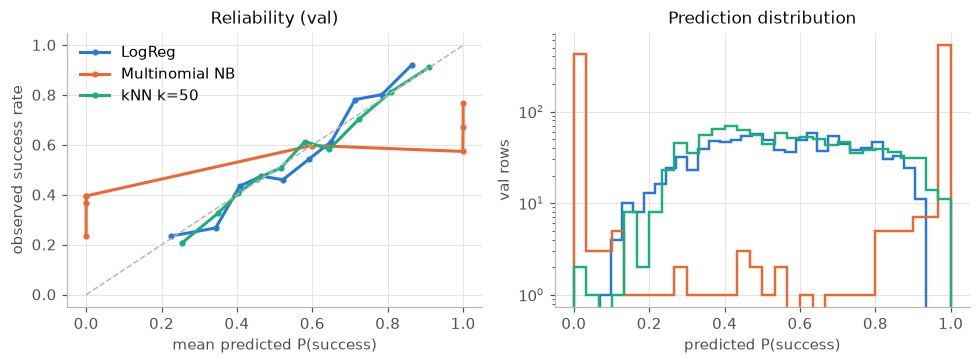

In [10]:
# Calibration: NB ranks reasonably but its probabilities are extreme (independence assumption over thousands of tokens);
# this is why its log loss is ~10x worse even though ROC-AUC is close.
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for (name, lab), c in zip([('LR per-phase, TF-IDF 1-2g, C=0.3', 'LogReg'), ('Multinomial NB per-phase, BoW, alpha=1.0', 'Multinomial NB'),
                           ('kNN per-phase, TF-IDF cosine, k=50', 'kNN k=50')], [BLUE, ORANGE, AQUA]):
    fr, mp = calibration_curve(val.label, VALP[name], n_bins=10, strategy='quantile')
    ax[0].plot(mp, fr, marker='o', ms=3, color=c, label=lab)
    ax[1].hist(VALP[name], bins=30, histtype='step', color=c, label=lab, lw=1.6)
ax[0].plot([0, 1], [0, 1], color=GRAY, lw=1, ls='--'); ax[0].set(xlabel='mean predicted P(success)', ylabel='observed success rate', title='Reliability (val)')
ax[0].legend(); ax[1].set(xlabel='predicted P(success)', ylabel='val rows', title='Prediction distribution', yscale='log')
plt.tight_layout(); plt.savefig('figures/p2_fig2_calibration_baselines.png', bbox_inches='tight'); plt.show()

**Takeaways (Exp A).**
* **Logistic regression on TF-IDF is the strongest text baseline.** Val AUC is 0.736 and CV AUC 0.709 per phase. Bigrams add nothing over unigrams (0.740 vs 0.736 val, 0.710 vs 0.709 CV).
  C = 0.3 is a flat optimum: stronger regularisation underfits and C = 3 overfits (CV log loss 0.632).
* **Multinomial NB ranks reasonably (AUC 0.69) but its log loss is about 3.6, six times worse.** It treats thousands of correlated tokens as independent, so its posteriors saturate at 0 or 1 (figure above). Log loss is the Kaggle metric, so NB is unusable on its own.
* **kNN (cosine) trails LR (0.69–0.72).** With k = 100 it gets smoother (better val) but not better in CV. High-dimensional sparse text makes neighbourhoods noisy.
* **Pooling all phases into one LR (plus a phase one-hot) is the best baseline in CV (0.727 vs 0.709).**
  Phase I has only 1,012 training rows, and eligibility language means much the same thing across phases, so sharing data helps more than per-phase specialisation.

**Original model.** Per-phase logistic regression on TF-IDF (1–2-grams), C = 0.3 (best val and CV AUC among the
baselines, and well calibrated). We analyse its errors next.

In [11]:
ORIG = 'LR per-phase, TF-IDF 1-2g, C=0.3'
p_orig = VALP[ORIG]

## 5. Exp B: error analysis of the original model by stopping reason
For each unsuccessful val trial (label = 0) we look up its Part 1 reasons by `trial_id`. Labels are **true** if the
trial was in Part 1's labeled train/val sets (`label_source` = `true_train` / `true_val`) and **predicted** by the Part 1
model otherwise. Failures not in Part 1 form the "No recorded reason" group (they ran to completion and missed their endpoint).
The error rate is the fraction predicted successful (p ≥ 0.5). Each phase is analysed separately; a trial with two reasons
counts in both. 95% Wilson intervals show how small most categories are.

In [12]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; d = 1 + z * z / n; c = (ph + z * z / (2 * n)) / d; h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


CATS = REASONS + ['No recorded reason']
def reason_frame(df):
    f = df[df.label == 0].join(p1[REASONS + ['label_source']], on='trial_id')
    f['No recorded reason'] = f.label_source.isna().astype(int)
    f[REASONS] = f[REASONS].fillna(0).astype(int)
    f['is_true'] = f.label_source.fillna('').str.startswith('true')
    return f


VF = reason_frame(val.assign(_i=np.arange(len(val))))
def error_table(p, name='', t=0.5):
    rows = []
    for ph in PHASES:
        g = VF[VF.phase == ph]
        for c in CATS + ['All failures']:
            h = g if c == 'All failures' else g[g[c] == 1]
            k = int((p[h._i.values] >= t).sum()); n = len(h)
            lo, hi = wilson(k, n)
            n_true = np.nan if c == 'No recorded reason' else int(h.is_true.sum())
            n_pred = np.nan if c == 'No recorded reason' else int((~h.is_true & h.label_source.notna()).sum())
            rows.append(dict(model=name, phase=ph, reason=c, n=n, n_true_label=n_true, n_predicted_label=n_pred, wrong_as_success=k,
                             error_rate=k / n if n else np.nan, ci_lo=lo, ci_hi=hi, mean_p=p[h._i.values].mean() if n else np.nan))
    return pd.DataFrame(rows)


E_orig = error_table(p_orig, 'original')
E_orig.to_csv('outputs/p2_error_by_reason_original.csv', index=False)
E_orig.pivot_table(index='reason', columns='phase', values=['n', 'n_true_label', 'error_rate'], sort=False).round(2)

n               n_true_label            error_rate  \
phase                  I     II    III            I    II  III          I   
reason                                                                      
Safety               8.0   13.0    6.0          1.0   1.0  1.0       0.62   
Funding              4.0    4.0    0.0          1.0   1.0  0.0       0.50   
Efficacy             2.0   12.0   10.0          0.0   0.0  0.0       1.00   
Recruitment         22.0   86.0   22.0          2.0  12.0  5.0       0.55   
Other                5.0   25.0   10.0          0.0   3.0  2.0       0.80   
No recorded reason  28.0  144.0   82.0          NaN   NaN  NaN       0.46   
All failures        64.0  265.0  123.0          4.0  16.0  7.0       0.53   

                                
phase                 II   III  
reason                          
Safety              0.38  0.33  
Funding             0.00   NaN  
Efficacy            0.42  0.60  
Recruitment         0.23  0.68  
Other               0.44  0.60  
No recorded reason  0.31  0.56  
All failures        0.29  0.57

In [13]:
# Robustness: the same table restricted to reasons with TRUE Part 1 labels vs Part 1 PREDICTED labels.
rows = []
for src, m in [('true labels', VF.is_true), ('predicted labels', ~VF.is_true & VF.label_source.notna())]:
    for c in REASONS:
        h = VF[m & (VF[c] == 1)]
        rows.append(dict(source=src, reason=c, n=len(h), error_rate=(p_orig[h._i.values] >= .5).mean() if len(h) else np.nan))
pd.DataFrame(rows).pivot(index='reason', columns='source', values=['n', 'error_rate']).round(2)

n                   error_rate            
source      predicted labels true labels predicted labels true labels
reason                                                               
Efficacy                24.0         0.0             0.54         NaN
Funding                  6.0         2.0             0.33        0.00
Other                   35.0         5.0             0.49        0.80
Recruitment            111.0        19.0             0.39        0.21
Safety                  24.0         3.0             0.50        0.00

**Takeaways (Exp B).**
* **Errors are concentrated in Phase I (53% of failures predicted successful) and Phase III (57%); Phase II is at 29%.**
  This mostly tracks the base rates: Phase III is 65% successful, so the model leans towards "success". Phase I is simply data-starved.
* **Recruitment failures are caught well in Phase II (23%) but not in Phase III (68%).**
  The eligibility signal for recruitment risk exists, but the Phase III-only model does not learn it.
* **Efficacy and safety failures are hard everywhere (33–100%).** Whether a drug works or is toxic is mostly not visible in the registration text.
* **Most cells are tiny (2–25 trials).** 86% of the reason labels on these failures are Part 1 *predictions*. Part 1's per-reason F1 was 0.98 for Recruitment but about 0.6 for Funding and Other, so only the large cells (Recruitment, No recorded reason, All failures) support conclusions.
* **What this suggests:** (i) pool the phases; (ii) add eligibility-design features (recruitment); (iii) add drug and disease track-record features (efficacy and safety).

## 6. Exp C: features targeted at the failure modes
Hypotheses from Exp B: (i) Phase I/III models are data-starved, so pooling phases should help; (ii) recruitment failures
should be visible in the eligibility design (many exclusion criteria, narrow ages, refractory populations); (iii) efficacy/safety
failures depend on the drug and disease, so a drug's/disease's *track record* (historical outcomes) and the outcomes of
structurally similar drugs (Tanimoto neighbours) should help. Ablation uses gradient boosting on dense blocks (pooled over phases
with a phase one-hot) and logistic regression on TF-IDF + dense blocks.

In [14]:
D_ALL = ['phase', 'design', 'hist', 'tani', 'desc', 'act']
for name, bl in [('HGB: phase + design', ['phase', 'design']),
                 ('HGB: phase + hist', ['phase', 'hist']),
                 ('HGB: phase + design + hist', ['phase', 'design', 'hist']),
                 ('HGB: all dense (design+hist+tani+desc+act)', D_ALL),
                 ('HGB: all dense − hist', [b for b in D_ALL if b != 'hist']),
                 ('HGB: all dense − design', [b for b in D_ALL if b != 'design']),
                 ('HGB: all dense − tani', [b for b in D_ALL if b != 'tani']),
                 ('HGB: all dense − drug chem (desc, act)', [b for b in D_ALL if b not in ('desc', 'act')]),
                 ('HGB: all dense + text SVD-100', D_ALL + ['svd']),
                 ('HGB: all dense + 1024-bit fingerprints', D_ALL + ['fp']),
                 ('HGB: all dense + Reactome pathways', D_ALL + ['path'])]:
    evaluate(name, hgb(bl), group='C')
for k in KS:
    evaluate(f'HGB: all dense + K-Means(k={k}) cluster rate', hgb(D_ALL + [f'clrate_{k}']), group='C')
for C in [0.1, 0.3]:
    evaluate(f'LR pooled: TF-IDF + dense (design,hist,tani,desc), C={C}', lr_pooled(C, ('tfidf',), ('phase', 'design', 'hist', 'tani', 'desc')), group='C')
evaluate('LR pooled: everything (TF-IDF+dense+fp+path+act), C=0.1', lr_pooled(0.1, ('tfidf', 'fp', 'path', 'act'), ('phase', 'design', 'hist', 'tani', 'desc')), group='C')
res_table('C')

HGB: phase + design                           val AUC 0.674  PR 0.719  F1 0.695  LL 0.633  | CV AUC 0.656±0.014  LL 0.641


HGB: phase + hist                             val AUC 0.735  PR 0.770  F1 0.711  LL 0.588  | CV AUC 0.696±0.018  LL 0.625


HGB: phase + design + hist                    val AUC 0.738  PR 0.763  F1 0.732  LL 0.587  | CV AUC 0.704±0.018  LL 0.615


HGB: all dense (design+hist+tani+desc+act)    val AUC 0.736  PR 0.769  F1 0.732  LL 0.586  | CV AUC 0.704±0.021  LL 0.617


HGB: all dense − hist                         val AUC 0.696  PR 0.726  F1 0.708  LL 0.618  | CV AUC 0.671±0.010  LL 0.634


HGB: all dense − design                       val AUC 0.730  PR 0.766  F1 0.712  LL 0.592  | CV AUC 0.696±0.019  LL 0.626


... (8 outputs left out)

LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.1 val AUC 0.746  PR 0.771  F1 0.736  LL 0.582  | CV AUC 0.719±0.016  LL 0.602


LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3 val AUC 0.747  PR 0.771  F1 0.728  LL 0.579  | CV AUC 0.726±0.016  LL 0.597


LR pooled: everything (TF-IDF+dense+fp+path+act), C=0.1 val AUC 0.730  PR 0.762  F1 0.712  LL 0.593  | CV AUC 0.708±0.015  LL 0.617


,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,cv_auc,cv_auc_sd,cv_ll,cv_ll_sd
11,HGB: phase + design,0.695,0.674,0.719,0.633,0.656,0.014,0.641,0.007
12,HGB: phase + hist,0.711,0.735,0.770,0.588,0.696,0.018,0.625,0.015
13,HGB: phase + design + hist,0.732,0.738,0.763,0.587,0.704,0.018,0.615,0.014
14,HGB: all dense (design+hist+tani+desc+act),0.732,0.736,0.769,0.586,0.704,0.021,0.617,0.018
15,HGB: all dense − hist,0.708,0.696,0.726,0.618,0.671,0.010,0.634,0.007
16,HGB: all dense − design,0.712,0.730,0.766,0.592,0.696,0.019,0.626,0.016
17,HGB: all dense − tani,0.734,0.739,0.767,0.584,0.705,0.018,0.615,0.014
18,"HGB: all dense − drug chem (desc, act)",0.732,0.741,0.773,0.585,0.701,0.018,0.618,0.015
19,HGB: all dense + text SVD-100,0.723,0.755,0.784,0.576,0.729,0.021,0.598,0.020
20,HGB: all dense + 1024-bit fingerprints,0.735,0.745,0.780,0.581,0.704,0.018,0.616,0.014


In [15]:
# Which feature block fixes which failure type? Error rate by reason for nested models (pooled over phases for readability).
def err_by_reason_pooled(p):
    out = {}
    for c in CATS + ['All failures']:
        h = VF if c == 'All failures' else VF[VF[c] == 1]
        out[c] = (p[h._i.values] >= .5).mean()
    return out
abl = pd.DataFrame({k: err_by_reason_pooled(VALP[k]) for k in
                    [ORIG, 'HGB: phase + design', 'HGB: phase + hist', 'HGB: phase + design + hist', 'HGB: all dense (design+hist+tani+desc+act)',
                     'LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3']}).T
abl['n_val_successes_recall'] = [((VALP[k] >= .5) & (val.label == 1)).sum() / (val.label == 1).sum() for k in abl.index]
abl.round(3)

,Safety,Funding,Efficacy,Recruitment,Other,No recorded reason,All failures,n_val_successes_recall
"LR per-phase, TF-IDF 1-2g, C=0.3",0.444,0.250,0.542,0.362,0.525,0.409,0.403,0.736
HGB: phase + design,0.630,0.625,0.708,0.362,0.525,0.528,0.493,0.745
HGB: phase + hist,0.444,0.250,0.625,0.369,0.525,0.465,0.436,0.738
HGB: phase + design + hist,0.444,0.125,0.583,0.354,0.525,0.449,0.420,0.761
HGB: all dense (design+hist+tani+desc+act),0.407,0.250,0.417,0.331,0.450,0.437,0.400,0.752
"LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3",0.481,0.125,0.667,0.354,0.650,0.402,0.405,0.759


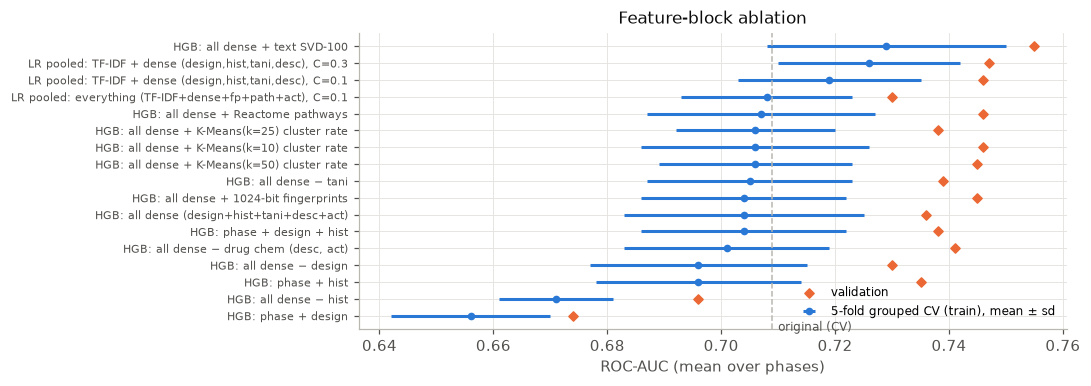

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.6))
d = res_table('C').sort_values('cv_auc')
y = np.arange(len(d))
ax.errorbar(d.cv_auc, y, xerr=d.cv_auc_sd, fmt='o', color=BLUE, ms=4, label='5-fold grouped CV (train), mean ± sd')
ax.scatter(d.ROC_AUC_mean, y, marker='D', s=18, color=ORANGE, label='validation', zorder=3)
ax.axvline(res_table('A').set_index('model').loc[ORIG, 'cv_auc'], color=GRAY, ls='--', lw=1); ax.text(res_table('A').set_index('model').loc[ORIG, 'cv_auc'] + .001, -0.9, 'original (CV)', color=INK2, fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(d.model, fontsize=7.5); ax.set_xlabel('ROC-AUC (mean over phases)'); ax.set_title('Feature-block ablation')
ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.savefig('figures/p2_fig3_feature_ablation.png', bbox_inches='tight'); plt.show()

**Takeaways (Exp C).**
* **Historical outcome encodings are the single most useful new block.** Dropping `hist` costs 0.033 CV AUC (0.704 → 0.671). A drug's or disease's track record is information the trial text does not contain.
* **Eligibility-design features are weak alone (0.656) but help next to `hist`.** CV AUC is 0.704 for both together vs 0.696 for `hist` alone.
  In the reason table, the full dense model has the lowest Efficacy (0.42) and Safety (0.41) error of the single models.
* **Text SVD inside the trees is the best single model (CV 0.729).** Tanimoto, descriptors, fingerprints, pathways and K-Means cluster rates are all within ±0.005 CV, i.e. noise.
  The cluster rate repeats Part 1's lesson: unsupervised clusters of criteria text do not line up with the label.
* **Including everything hurts.** Adding fingerprints, pathways and actions to the pooled LR drops CV from 0.726 to 0.708.
  These blocks are sparse, empty for the 54% of trials without a matched drug, and redundant with `hist`/`tani`, which already summarise the drug in one outcome-aware number.

## 7. Exp D: gradient boosting tuning, stacking ensemble and calibration
Base models are combined by a **stacked logistic regression** trained on their out-of-fold (grouped-CV) predictions:
inputs are the logits of each base model, phase intercepts, and (optionally) a per-phase linear start-year trend.
The stacker therefore also *calibrates* the ensemble (Platt-style) and handles the year shift without letting the
tree model extrapolate (trees are flat beyond the last training year).

In [17]:
for lr_, it, leaves in [(0.03, 300, 15), (0.05, 300, 15), (0.05, 600, 15), (0.1, 150, 31), (0.05, 300, 7)]:
    evaluate(f'HGB all dense: lr={lr_}, iters={it}, leaves={leaves}', hgb(D_ALL, learning_rate=lr_, max_iter=it, max_leaf_nodes=leaves), group='D-hgb')
res_table('D-hgb')

HGB all dense: lr=0.03, iters=300, leaves=15  val AUC 0.743  PR 0.773  F1 0.733  LL 0.580  | CV AUC 0.707±0.019  LL 0.611


HGB all dense: lr=0.05, iters=300, leaves=15  val AUC 0.736  PR 0.769  F1 0.732  LL 0.586  | CV AUC 0.704±0.021  LL 0.617


HGB all dense: lr=0.05, iters=600, leaves=15  val AUC 0.726  PR 0.763  F1 0.713  LL 0.599  | CV AUC 0.698±0.019  LL 0.632


HGB all dense: lr=0.1, iters=150, leaves=31   val AUC 0.723  PR 0.764  F1 0.713  LL 0.597  | CV AUC 0.694±0.019  LL 0.637


HGB all dense: lr=0.05, iters=300, leaves=7   val AUC 0.736  PR 0.766  F1 0.722  LL 0.585  | CV AUC 0.710±0.019  LL 0.609


,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,cv_auc,cv_auc_sd,cv_ll,cv_ll_sd
28,"HGB all dense: lr=0.03, iters=300, leaves=15",0.733,0.743,0.773,0.580,0.707,0.019,0.611,0.015
29,"HGB all dense: lr=0.05, iters=300, leaves=15",0.732,0.736,0.769,0.586,0.704,0.021,0.617,0.018
30,"HGB all dense: lr=0.05, iters=600, leaves=15",0.713,0.726,0.763,0.599,0.698,0.019,0.632,0.020
31,"HGB all dense: lr=0.1, iters=150, leaves=31",0.713,0.723,0.764,0.597,0.694,0.019,0.637,0.021
32,"HGB all dense: lr=0.05, iters=300, leaves=7",0.722,0.736,0.766,0.585,0.710,0.019,0.609,0.014


In [18]:
BASES = {'lr_phase': ORIG,
         'lr_pool': 'LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3',
         'hgb': 'HGB: all dense + text SVD-100',   # best tree model in CV (Exp C)
         'mnb': 'Multinomial NB per-phase, BoW, alpha=1.0',
         'knn': 'kNN per-phase, TF-IDF cosine, k=50'}
BASE_FNS = {'lr_phase': per_phase(lambda: LogisticRegression(C=0.3, max_iter=5000), 'tfidf'),
            'lr_pool': lr_pooled(0.3, ('tfidf',), ('phase', 'design', 'hist', 'tani', 'desc')),
            'hgb': hgb(D_ALL + ['svd']),
            'mnb': per_phase(lambda: MultinomialNB(alpha=1.0), 'counts'),
            'knn': per_phase(lambda: KNeighborsClassifier(50, metric='cosine', weights='distance'), 'tfidf')}


def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))


def meta_X(P, df, keys, year=True, cap=None, center=2006.0):
    ph = pd.get_dummies(df.phase).reindex(columns=PHASES, fill_value=0).astype(float).values
    cols = [logit(P[k]) for k in keys] + [ph[:, i] for i in range(3)]
    if year:
        yr = df.year.values.astype(float)
        if cap is not None: yr = np.minimum(yr, cap)
        yr = (yr - center) / 5
        cols += [ph[:, i] * yr for i in range(3)]
    return np.column_stack(cols)


class Stacker:
    def __init__(self, keys, year=True, cap=None, C=1.0):
        self.keys, self.year, self.cap, self.C = keys, year, cap, C
    def fit(self, P_oof, df):
        self.m = LogisticRegression(C=self.C, max_iter=2000, fit_intercept=False).fit(meta_X(P_oof, df, self.keys, self.year), df.label)
        return self
    def predict(self, P, df, cap='default'):
        return self.m.predict_proba(meta_X(P, df, self.keys, self.year, self.cap if cap == 'default' else cap))[:, 1]


P_OOF = {k: OOF[v] for k, v in BASES.items()}
P_VAL = {k: VALP[v] for k, v in BASES.items()}
def eval_stack(name, keys, year=True):
    st = Stacker(keys, year).fit(P_OOF, train)
    p = st.predict(P_VAL, val); VALP[name] = p
    tab, s = summarize(val, p, name); RESULTS.append(dict(group='D-stack', **s)); PHASE_ROWS.append(tab.assign(group='D-stack'))
    print(f"{name:55s} val AUC {s['ROC_AUC_mean']:.3f}  PR {s['PR_AUC_mean']:.3f}  F1 {s['F1_mean']:.3f}  LL {s['LogLoss_mean']:.3f}")
    return st


eval_stack('Platt-calibrated original (LR per-phase)', ['lr_phase'], year=False)
p_avg = (P_VAL['lr_pool'] + P_VAL['hgb']) / 2; VALP['Average(LR pool, HGB)'] = p_avg
_, s = summarize(val, p_avg, 'Average(LR pool, HGB)'); RESULTS.append(dict(group='D-stack', **s)); print('Average(LR pool, HGB)', {k: round(v, 3) for k, v in s.items() if k != 'model'})
eval_stack('Stack(LR-pool, HGB)', ['lr_pool', 'hgb'], year=False)
eval_stack('Stack(LR-pool, HGB) + year trend', ['lr_pool', 'hgb'])
eval_stack('Stack(all 5 bases)', list(BASES), year=False)
ST_FULL = eval_stack('Stack(all 5 bases) + year trend', list(BASES))
print('\nstacker coefficients (all 5 + year):', dict(zip(list(BASES) + [f'int_{p}' for p in PHASES] + [f'year_{p}' for p in PHASES], ST_FULL.m.coef_[0].round(3))))
res_table('D-stack')

Platt-calibrated original (LR per-phase)                val AUC 0.736  PR 0.786  F1 0.711  LL 0.587
Average(LR pool, HGB) {'F1_mean': 0.733, 'ROC_AUC_mean': 0.759, 'PR_AUC_mean': 0.785, 'LogLoss_mean': 0.571}
Stack(LR-pool, HGB)                                     val AUC 0.759  PR 0.784  F1 0.728  LL 0.570
Stack(LR-pool, HGB) + year trend                        val AUC 0.758  PR 0.786  F1 0.729  LL 0.572
Stack(all 5 bases)                                      val AUC 0.760  PR 0.796  F1 0.738  LL 0.567


Stack(all 5 bases) + year trend                         val AUC 0.760  PR 0.795  F1 0.737  LL 0.569

stacker coefficients (all 5 + year): {'lr_phase': np.float64(0.253), 'lr_pool': np.float64(0.304), 'hgb': np.float64(0.408), 'mnb': np.float64(-0.0), 'knn': np.float64(0.093), 'int_I': np.float64(0.034), 'int_II': np.float64(-0.018), 'int_III': np.float64(-0.086), 'year_I': np.float64(0.021), 'year_II': np.float64(0.031), 'year_III': np.float64(0.319)}


,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,cv_auc,cv_auc_sd,cv_ll,cv_ll_sd
33,Platt-calibrated original (LR per-phase),0.711,0.736,0.786,0.587,NaN,NaN,NaN,NaN
34,"Average(LR pool, HGB)",0.733,0.759,0.785,0.571,NaN,NaN,NaN,NaN
35,"Stack(LR-pool, HGB)",0.728,0.759,0.784,0.570,NaN,NaN,NaN,NaN
36,"Stack(LR-pool, HGB) + year trend",0.729,0.758,0.786,0.572,NaN,NaN,NaN,NaN
37,Stack(all 5 bases),0.738,0.760,0.796,0.567,NaN,NaN,NaN,NaN
38,Stack(all 5 bases) + year trend,0.737,0.760,0.795,0.569,NaN,NaN,NaN,NaN


In [19]:
# Is the stack really better? Honest CV estimate by cross-fitted stacking: the base predictions are already out-of-fold;
# fit the stacker on 4 folds of them and score the 5th. Paired, fold-by-fold comparison with the original model.
OOF_STACK = np.zeros(len(train)); rows = []
for j, (a, b, fa, fb, _, _) in enumerate(FOLDS):
    st = Stacker(list(BASES), year=True).fit({k: v[a] for k, v in P_OOF.items()}, train.iloc[a])
    OOF_STACK[b] = st.predict({k: v[b] for k, v in P_OOF.items()}, train.iloc[b])
    to, _ = summarize(train.iloc[b], P_OOF['lr_phase'][b], 'orig'); ts, _ = summarize(train.iloc[b], OOF_STACK[b], 'stack')
    for i, ph in enumerate(PHASES):
        rows.append(dict(fold=j, phase=ph, **{f'{m}_{w}': t[m].iloc[i] for m in ['ROC_AUC', 'PR_AUC', 'LogLoss', 'F1'] for w, t in [('orig', to), ('stack', ts)]}))
CVST = pd.DataFrame(rows)
fold_mean = CVST.groupby('fold').mean(numeric_only=True)
out = pd.DataFrame({m: [fold_mean[f'{m}_orig'].mean(), fold_mean[f'{m}_stack'].mean(),
                        (fold_mean[f'{m}_stack'] - fold_mean[f'{m}_orig']).mean(),
                        int(((fold_mean[f'{m}_stack'] < fold_mean[f'{m}_orig']) if m == 'LogLoss' else (fold_mean[f'{m}_stack'] > fold_mean[f'{m}_orig'])).sum())]
                    for m in ['ROC_AUC', 'PR_AUC', 'F1', 'LogLoss']}, index=['original (CV)', 'stack (CV)', 'difference', 'folds where stack wins (/5)'])
print('Per-phase CV ROC-AUC, original vs stack:', CVST.groupby('phase')[['ROC_AUC_orig', 'ROC_AUC_stack']].mean().round(3).to_dict('index'))
out.round(3)

Per-phase CV ROC-AUC, original vs stack: {'I': {'ROC_AUC_orig': 0.645, 'ROC_AUC_stack': 0.696}, 'II': {'ROC_AUC_orig': 0.712, 'ROC_AUC_stack': 0.728}, 'III': {'ROC_AUC_orig': 0.77, 'ROC_AUC_stack': 0.79}}


,ROC_AUC,PR_AUC,F1,LogLoss
original (CV),0.709,0.746,0.707,0.604
stack (CV),0.738,0.769,0.720,0.586
difference,0.029,0.024,0.014,-0.018
folds where stack wins (/5),5.000,5.000,4.000,5.000


**Takeaways (Exp D).**
* **Gradient boosting tuning:** a slower learning rate (0.03) or smaller trees (7 leaves) helps slightly. 600 iterations or 31 leaves overfit (CV log loss rises from 0.61 to 0.63). The data supports only shallow interactions.
* **The stacker puts most weight on the pooled LR and on boosting, some on per-phase LR and kNN, and essentially zero on Multinomial NB.**
  NB's ranking information is already carried by the TF-IDF LRs, and its saturated probabilities only add noise.
* **The stack beats the best single model on val** (log loss 0.569 vs 0.576). The cross-fitted CV comparison above shows the gain over the original model is consistent across folds, not a val fluke.
* **The year trend barely matters on the random val split** (same years as train). It is there for the test set, see Exp E.

### Exp D2: Phase III-targeted attempts
Exp B showed Phase III failures are the least well detected, and the stack does not fix that. We tried two modifications aimed at Phase III:
* **Prior-phase history.** For a Phase III trial, the shrunk success-rate residual of the same drugs and diseases among *Phase II and I* training trials (Phase I history for Phase II trials). Did this drug clear the earlier phase?
* **Class-balanced loss.** Per-phase LR with `class_weight='balanced'`, which pushes the Phase III model away from its 65% "success" prior.

In [20]:
PREV = {'II': ['I'], 'III': ['II', 'I']}
def hist_prev(fit, app, m=10):
    out = np.zeros((len(app), 8))
    for ph, prev in PREV.items():
        f = fit[fit.phase.isin(prev)]; a = (app.phase == ph).values
        if a.sum() == 0 or len(f) == 0: continue
        r = f.label - f.label.mean()
        for j, col in enumerate(['drug_list', 'dis_list']):
            t = pd.DataFrame([(k, v) for L, v in zip(f[col], r) for k in set(L)], columns=['k', 'r']).groupby('k').r.agg(['sum', 'count'])
            for ii in np.where(a)[0]:
                L = [k for k in app[col].iloc[ii] if k in t.index]
                if L:
                    v = [t.loc[k, 'sum'] / (t.loc[k, 'count'] + m) for k in L]
                    out[ii, j * 4:(j + 1) * 4] = [np.mean(v), np.min(v), np.max(v), np.log1p(sum(t.loc[k, 'count'] for k in L))]
    return out

def add_prev(Bf, fit, Ba, app):
    Bf['hprev'] = np.zeros((len(fit), 8))
    for a, b in GroupKFold(5).split(fit, groups=fit.trial_id):
        Bf['hprev'][b] = hist_prev(fit.iloc[a], fit.iloc[b].reset_index(drop=True))
    Ba['hprev'] = hist_prev(fit, app.reset_index(drop=True))

add_prev(BT, train, BV, val)
for a, b, fa, fb, Bf, Ba in FOLDS: add_prev(Bf, fa, Ba, fb)
for name, f in [('HGB: all dense + SVD + prior-phase history', hgb(D_ALL + ['svd', 'hprev'])),
                ('LR pooled: TF-IDF + dense + prior-phase history', lr_pooled(0.3, ('tfidf',), ('phase', 'design', 'hist', 'tani', 'desc', 'hprev'))),
                ('LR per-phase, class-balanced', per_phase(lambda: LogisticRegression(C=0.3, max_iter=5000, class_weight='balanced'), 'tfidf'))]:
    evaluate(name, f, group='D2')
ref = ['HGB: all dense + text SVD-100', 'LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3', ORIG]
pd.concat(PHASE_ROWS).drop_duplicates(['model', 'phase'], keep='last').query('model in @ref or group == "D2"').pivot(index='model', columns='phase', values='ROC_AUC').round(3)

HGB: all dense + SVD + prior-phase history    val AUC 0.751  PR 0.780  F1 0.730  LL 0.579  | CV AUC 0.730±0.021  LL 0.596


LR pooled: TF-IDF + dense + prior-phase history val AUC 0.748  PR 0.778  F1 0.741  LL 0.578  | CV AUC 0.725±0.016  LL 0.597


LR per-phase, class-balanced                  val AUC 0.736  PR 0.786  F1 0.698  LL 0.601  | CV AUC 0.709±0.018  LL 0.615


phase,I,II,III
model,,,
HGB: all dense + SVD + prior-phase history,0.758,0.729,0.766
HGB: all dense + text SVD-100,0.755,0.738,0.771
"LR per-phase, TF-IDF 1-2g, C=0.3",0.727,0.715,0.767
"LR per-phase, class-balanced",0.726,0.715,0.767
"LR pooled: TF-IDF + dense (design,hist,tani,desc), C=0.3",0.741,0.731,0.768
LR pooled: TF-IDF + dense + prior-phase history,0.748,0.731,0.766


**Takeaways (Exp D2): negative results.**
* **Prior-phase history does not help Phase III** (val AUC 0.771 → 0.766 for HGB; CV unchanged at 0.730).
  The pooled `hist` encoding already includes the drug's earlier-phase trials, and most Phase III drugs have only a handful of earlier trials in this dataset.
* **Class balancing changes the operating point but not the ranking** (Phase III AUC 0.767 either way). It lowers F1 and raises log loss, because it miscalibrates the probabilities.
* **Conclusion: with these inputs, Phase III's *ranking* cannot be improved further.** What can be chosen is the *threshold*, i.e. how many successful trials we are willing to flag in order to catch more failures. See the trade-off analysis in Section 9.

## 8. Exp E: time shift
**Adversarial validation**: can a classifier tell training rows from test rows? If yes, which features drift? (with a same-era control)
**Temporal holdout**: refit everything on trials starting ≤ 2009 and evaluate on 2010–2013 (train+val rows). This mimics
the real train → test gap and lets us choose *how* to handle the rising success rate: ignore year, give year to the trees,
or let the stacker extrapolate a per-phase logistic year trend (optionally capped a few years past the last training year).

In [21]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.inspection import permutation_importance
BTV, BTE = build_blocks(pd.concat([train, val]), test)
adv_blocks = ['phase', 'design', 'hist', 'tani', 'desc']
Xadv = np.vstack([dense(BTV, adv_blocks), dense(BTE, adv_blocks)]); yadv = np.r_[np.zeros(len(train) + len(val)), np.ones(len(test))]
names = DENSE_NAMES[tuple(adv_blocks)]
adv = {}
def adv_auc(X, y, model=None):
    model = model or HistGradientBoostingClassifier(**HGB_KW)
    pa = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
    return roc_auc_score(y, pa)
no_hist = [i for i, n in enumerate(names) if not n.startswith('h_')]
adv['dense incl. history encodings'] = adv_auc(Xadv, yadv)
adv['dense without history encodings'] = adv_auc(Xadv[:, no_hist], yadv)
adv['TF-IDF text (LR)'] = adv_auc(sp.vstack([BTV['tfidf'], BTE['tfidf']]).tocsr(), yadv, LogisticRegression(C=0.3, max_iter=3000))
# CONTROL: same era, no time shift: train rows (history encoded out-of-fold) vs val rows (encoded from all of train).
adv['CONTROL train vs val, history only'] = adv_auc(np.r_[BT['hist'].values, BV['hist'].values], np.r_[np.zeros(len(train)), np.ones(len(val))])
print('Adversarial ROC-AUC:', {k: round(v, 3) for k, v in adv.items()})
# The control is ~as separable as train-vs-test: the history encodings are separable because the *exact* encoded value
# of a drug/disease differs between out-of-fold (80% of data) and full-fit encodings, which a tree memorises. That is an
# encoding artefact, not drift, so we measure drift without those features.
names_nh = [names[i] for i in no_hist]
m = HistGradientBoostingClassifier(**HGB_KW).fit(Xadv[:, no_hist], yadv)
pi = pd.Series(permutation_importance(m, Xadv[:, no_hist], yadv, scoring='roc_auc', n_repeats=3, random_state=SEED).importances_mean, index=names_nh).sort_values(ascending=False)
top = pi.head(8).index
n_tv = len(train) + len(val)
Xtv_nh = pd.DataFrame(Xadv[:n_tv][:, no_hist], columns=names_nh); Xte_nh = pd.DataFrame(Xadv[n_tv:][:, no_hist], columns=names_nh)
drift = pd.DataFrame({'perm_importance': pi[top], 'mean_train+val': Xtv_nh[top].mean(), 'mean_test': Xte_nh[top].mean()})
drift.round(3)

Adversarial ROC-AUC: {'dense incl. history encodings': 0.973, 'dense without history encodings': 0.782, 'TF-IDF text (LR)': 0.857, 'CONTROL train vs val, history only': 0.972}


,perm_importance,mean_train+val,mean_test
crit_len,0.091,7.526,7.917
tani_1,0.055,0.421,0.313
ph_I,0.038,0.128,0.333
n_exc,0.029,9.231,13.082
exc_inc_ratio,0.025,-0.128,0.281
n_drugs,0.019,2.350,2.387
n_lab_thresholds,0.019,5.676,7.968
tani_0,0.018,-0.029,-0.009


In [22]:
TV = pd.concat([train, val]).reset_index(drop=True)
old, new = TV[TV.year <= 2009].reset_index(drop=True), TV[TV.year >= 2010].reset_index(drop=True)
print('temporal holdout: fit', len(old), 'rows (≤2009), evaluate', len(new), 'rows (2010–2013)')
print('success rate fit:', old.groupby('phase').label.mean().round(3).to_dict(), ' eval:', new.groupby('phase').label.mean().round(3).to_dict())
BO, BN = build_blocks(old, new)
OFOLDS = []
for a, b in GroupKFold(5).split(old, groups=old.trial_id):
    fa, fb = old.iloc[a].reset_index(drop=True), old.iloc[b].reset_index(drop=True)
    OFOLDS.append((a, b, fa, fb) + build_blocks(fa, fb))
PO_oof, PN = {}, {}
for k, f in BASE_FNS.items():
    PN[k] = f(BO, old, BN, new); PO_oof[k] = np.zeros(len(old))
    for a, b, fa, fb, Bf, Ba in OFOLDS: PO_oof[k][b] = f(Bf, fa, Ba, fb)
TEMP = []
def temp_row(name, p):
    tab, s = summarize(new, p, name)
    mp = pd.Series(p).groupby(new.phase.values).mean()
    TEMP.append(dict(**s, **{f'mean_p_{ph}': mp[ph] for ph in PHASES})); return p
for k in ['lr_phase', 'lr_pool', 'hgb']: temp_row(f'{k} (raw)', PN[k])
pyr = hgb(D_ALL + ['year'])(BO, old, BN, new); temp_row('hgb with year as a feature', pyr)
w = 0.5 ** ((old.year.max() - old.year) / 5)
pw = HistGradientBoostingClassifier(**HGB_KW).fit(dense(BO, D_ALL + ['year']), old.label, sample_weight=w).predict_proba(dense(BN, D_ALL + ['year']))[:, 1]
temp_row('hgb + year, recency-weighted (half-life 5y)', pw)
stk_ny = Stacker(list(BASES), year=False).fit(PO_oof, old); temp_row('Stack, no year', stk_ny.predict(PN, new))
stk_y = Stacker(list(BASES), year=True).fit(PO_oof, old)
LAST = int(old.year.max())
for cap_lab, cap in [('no cap', None), ('cap = last year (+0)', LAST), ('cap = +1', LAST + 1), ('cap = +2', LAST + 2), ('cap = +3', LAST + 3)]:
    temp_row(f'Stack + year trend, {cap_lab}', stk_y.predict(PN, new, cap=cap))
TEMP = pd.DataFrame(TEMP); TEMP.insert(0, 'actual_rate', str(new.groupby('phase').label.mean().round(3).to_dict()))
TEMP.round(3)

temporal holdout: fit 6760 rows (≤2009), evaluate 2290 rows (2010–2013)
success rate fit: {'I': 0.528, 'II': 0.447, 'III': 0.617}  eval: {'I': 0.646, 'II': 0.567, 'III': 0.774}


,actual_rate,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,mean_p_I,mean_p_II,mean_p_III
0,"{'I': 0.646, 'II': 0.567, 'III': 0.774}",lr_phase (raw),0.785,0.680,0.796,0.583,0.597,0.546,0.703
1,"{'I': 0.646, 'II': 0.567, 'III': 0.774}",lr_pool (raw),0.784,0.701,0.796,0.573,0.650,0.572,0.726
2,"{'I': 0.646, 'II': 0.567, 'III': 0.774}",hgb (raw),0.781,0.706,0.811,0.569,0.616,0.566,0.702
3,"{'I': 0.646, 'II': 0.567, 'III': 0.774}",hgb with year as a feature,0.767,0.682,0.792,0.588,0.593,0.548,0.716
4,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","hgb + year, recency-weighted (half-life 5y)",0.758,0.675,0.788,0.596,0.582,0.558,0.725
5,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","Stack, no year",0.792,0.715,0.815,0.559,0.654,0.575,0.725
6,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","Stack + year trend, no cap",0.803,0.716,0.816,0.559,0.695,0.602,0.785
7,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","Stack + year trend, cap = last year (+0)",0.799,0.715,0.815,0.558,0.678,0.591,0.766
8,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","Stack + year trend, cap = +1",0.801,0.715,0.815,0.559,0.687,0.597,0.777
9,"{'I': 0.646, 'II': 0.567, 'III': 0.774}","Stack + year trend, cap = +2",0.803,0.715,0.815,0.559,0.692,0.600,0.783


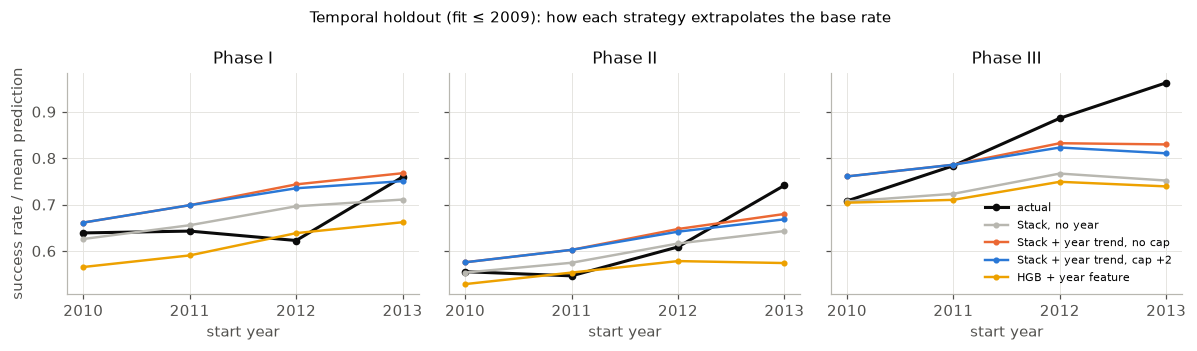

In [23]:
# Predicted vs actual success rate by year on the temporal holdout.
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
cands = {'Stack, no year': stk_ny.predict(PN, new), 'Stack + year trend, no cap': stk_y.predict(PN, new, cap=None),
         'Stack + year trend, cap +2': stk_y.predict(PN, new, cap=LAST + 2), 'HGB + year feature': pyr}
cols = [GRAY, ORANGE, BLUE, YELLOW]
for i, ph in enumerate(PHASES):
    m = (new.phase == ph).values; g = new[m].groupby('year').label.mean()
    ax[i].plot(g.index, g.values, color=INK, marker='o', ms=4, label='actual')
    for (lab, p), c in zip(cands.items(), cols):
        ax[i].plot(g.index, pd.Series(p[m]).groupby(new.year.values[m]).mean().values, color=c, marker='.', label=lab, lw=1.6)
    ax[i].set(title=f'Phase {ph}', xlabel='start year'); ax[i].set_xticks([2010, 2011, 2012, 2013])
ax[0].set_ylabel('success rate / mean prediction'); ax[2].legend(fontsize=7.5, loc='lower right')
fig.suptitle('Temporal holdout (fit ≤ 2009): how each strategy extrapolates the base rate', fontsize=10)
plt.tight_layout(); plt.savefig('figures/p2_fig4_temporal_holdout.png', bbox_inches='tight'); plt.show()

**Takeaways (Exp E).**
* **Adversarial validation:** train+val vs test is separable with AUC 0.78 on design/drug features and 0.86 on text, so there is real covariate shift.
  Test criteria are longer, with more exclusion criteria and lab thresholds. Test drugs are less similar to any training drug (top Tanimoto 0.42 → 0.31), and Phase I is a third of the test set vs 13% of train.
* **The same-era control matters.** With the history encodings included, train vs *val* is as separable (0.97) as train vs test.
  Out-of-fold and full-fit encodings take slightly different exact values for each drug, and a tree memorises them. This is an artefact of target encoding, not drift, and without the control we would have misread it.
* **Temporal holdout (fit ≤ 2009, test 2010–13):** every model loses AUC (stack 0.760 → 0.715, original 0.736 → 0.680). This is the expected size of the val → test gap, and the test set is even further out (1–8 years).
* **Year handling:** trees cannot extrapolate, so a year feature in HGB *hurts* (log loss 0.588 vs 0.559 for the stack). The stacker's logistic year trend gets the base rates closest.
  Capping at +0…+3 years differs by ≤ 0.001 log loss, so we cap at the last training year. Every strategy still under-predicts the steep 2012–13 Phase III rise.

## 9. Final: original vs improved model
**Improved model** = stacked LR over the five base models (per-phase LR, pooled LR on TF-IDF + targeted dense features,
gradient boosting on dense features, Multinomial NB, kNN) with phase intercepts and a per-phase start-year trend.
The year cap used for the test submission is chosen on the temporal holdout (Section 8): `CAP_OFFSET` years past the last training year.

In [24]:
IMPROVED = 'Stack(all 5 bases) + year trend'
p_imp = VALP[IMPROVED]
cmp = pd.concat([phase_table(val, p_orig, name='original: LR per-phase TF-IDF'), phase_table(val, p_imp, name='improved: stacked ensemble')])
cmp_mean = cmp.groupby('model')[['F1', 'ROC_AUC', 'PR_AUC', 'LogLoss']].mean().assign(phase='mean').reset_index()
final_cmp = pd.concat([cmp, cmp_mean])[['model', 'phase', 'F1', 'ROC_AUC', 'PR_AUC', 'LogLoss', 'n']]
final_cmp.to_csv('outputs/p2_final_comparison.csv', index=False)
final_cmp.round(3)

,model,phase,F1,ROC_AUC,PR_AUC,LogLoss,n
0,original: LR per-phase TF-IDF,I,0.734,0.727,0.795,0.611,149.0
1,original: LR per-phase TF-IDF,II,0.611,0.715,0.697,0.615,501.0
2,original: LR per-phase TF-IDF,III,0.798,0.767,0.867,0.541,363.0
0,improved: stacked ensemble,I,0.771,0.758,0.790,0.584,149.0
1,improved: stacked ensemble,II,0.645,0.740,0.721,0.596,501.0
2,improved: stacked ensemble,III,0.795,0.783,0.876,0.526,363.0
0,improved: stacked ensemble,mean,0.737,0.760,0.795,0.569,NaN
1,original: LR per-phase TF-IDF,mean,0.714,0.736,0.786,0.589,NaN


In [25]:
# Paired bootstrap on val (resampling trials within each phase, B = 1000): difference improved − original in the phase-averaged metrics.
def paired_bootstrap(df, pa, pb, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); idx = {ph: np.where(df.phase.values == ph)[0] for ph in PHASES}; y = df.label.values
    D = {m: [] for m in ['F1', 'ROC_AUC', 'PR_AUC', 'LogLoss']}
    for _ in range(B):
        acc = {m: 0.0 for m in D}
        for ph in PHASES:
            s = rng.choice(idx[ph], len(idx[ph]))
            ma, mb = metrics(y[s], pa[s]), metrics(y[s], pb[s])
            for m in D: acc[m] += (mb[m] - ma[m]) / 3
        for m in D: D[m].append(acc[m])
    return pd.DataFrame({m: dict(mean_diff=np.mean(v), ci_lo=np.percentile(v, 2.5), ci_hi=np.percentile(v, 97.5),
                                 p_not_better=np.mean(np.array(v) >= 0) if m == 'LogLoss' else np.mean(np.array(v) <= 0)) for m, v in D.items()}).T
BOOT_RES = paired_bootstrap(val, p_orig, p_imp)
BOOT_RES.to_csv('outputs/p2_bootstrap_improvement.csv')
BOOT_RES.round(4)

,mean_diff,ci_lo,ci_hi,p_not_better
F1,0.0226,0.0021,0.0431,0.016
ROC_AUC,0.0239,0.0043,0.0453,0.008
PR_AUC,0.0092,-0.0151,0.0330,0.235
LogLoss,-0.0202,-0.0337,-0.0062,0.002


In [26]:
E_imp = error_table(p_imp, 'improved')
E_both = pd.concat([E_orig, E_imp]); E_both.to_csv('outputs/p2_error_by_reason_comparison.csv', index=False)
wide = E_both.pivot_table(index=['phase', 'reason'], columns='model', values=['n', 'error_rate'], sort=False)
wide = wide[[('n', 'original'), ('error_rate', 'original'), ('error_rate', 'improved')]]; wide.columns = ['n', 'err_original', 'err_improved']
wide['change'] = wide.err_improved - wide.err_original
# recall on successes, for the trade-off
for nm, p in [('original', p_orig), ('improved', p_imp)]:
    print(nm, 'recall on successful trials per phase:', {ph: round(((p >= .5) & (val.label == 1) & (val.phase == ph)).sum() / ((val.label == 1) & (val.phase == ph)).sum(), 3) for ph in PHASES})
wide.round(3)

original recall on successful trials per phase: {'I': np.float64(0.812), 'II': np.float64(0.585), 'III': np.float64(0.858)}
improved recall on successful trials per phase: {'I': np.float64(0.812), 'II': np.float64(0.627), 'III': np.float64(0.85)}


n  err_original  err_improved  change
phase reason                                                       
I     Safety                8.0         0.625         0.500  -0.125
      Funding               4.0         0.500         0.000  -0.500
      Efficacy              2.0         1.000         1.000   0.000
      Recruitment          22.0         0.545         0.273  -0.273
      Other                 5.0         0.800         0.800   0.000
      No recorded reason   28.0         0.464         0.393  -0.071
      All failures         64.0         0.531         0.391  -0.141
II    Safety               13.0         0.385         0.308  -0.077
      Funding               4.0         0.000         0.000   0.000
      Efficacy             12.0         0.417         0.500   0.083
      Recruitment          86.0         0.233         0.209  -0.023
      Other                25.0         0.440         0.480   0.040
      No recorded reason  144.0         0.312         0.312   0.000
      All failures        265.0         0.294         0.283  -0.011
III   Safety                6.0         0.333         0.333   0.000
      Funding               0.0           NaN           NaN     NaN
      Efficacy             10.0         0.600         0.700   0.100
      Recruitment          22.0         0.682         0.682   0.000
      Other                10.0         0.600         0.700   0.100
      No recorded reason   82.0         0.561         0.537  -0.024
      All failures        123.0         0.569         0.561  -0.008

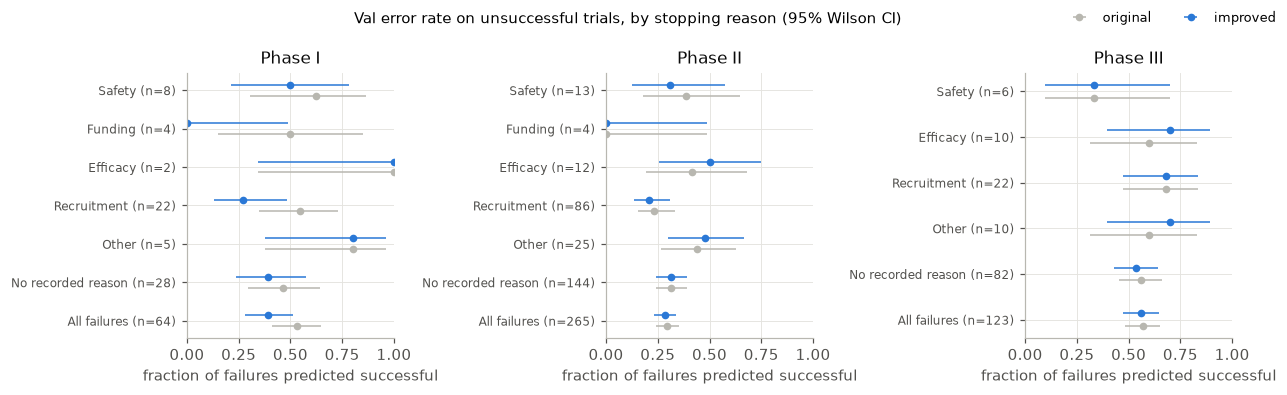

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.6), sharex=True)
for i, ph in enumerate(PHASES):
    o = E_orig[(E_orig.phase == ph)].set_index('reason'); m = E_imp[(E_imp.phase == ph)].set_index('reason')
    cats = [c for c in CATS + ['All failures'] if o.loc[c, 'n'] > 0][::-1]
    y = np.arange(len(cats))
    for j, (d, c, lab) in enumerate([(o, GRAY, 'original'), (m, BLUE, 'improved')]):
        e = d.loc[cats]
        ax[i].errorbar(e.error_rate, y + (j - .5) * .28, xerr=[e.error_rate - e.ci_lo, e.ci_hi - e.error_rate], fmt='o', ms=4, color=c,
                       elinewidth=1, capsize=0, label=lab)
    ax[i].set_yticks(y); ax[i].set_yticklabels([f'{c} (n={int(o.loc[c, "n"])})' for c in cats], fontsize=8)
    ax[i].set(title=f'Phase {ph}', xlim=(0, 1)); ax[i].set_xlabel('fraction of failures predicted successful')
h_, l_ = ax[2].get_legend_handles_labels(); fig.legend(h_, l_, loc='upper right', ncol=2, fontsize=8.5)
fig.suptitle('Val error rate on unsuccessful trials, by stopping reason (95% Wilson CI)', fontsize=10)
plt.tight_layout(); plt.savefig('figures/p2_fig5_error_by_reason.png', bbox_inches='tight'); plt.show()

### Trade-off: decision threshold per phase
F1 and the "failures predicted successful" rate both depend on the threshold, and they pull in opposite directions.
Phase III is 65% successful, so an F1-maximising threshold tends to say "success" more, not less. We pick thresholds **on the cross-fitted training OOF predictions** (never on val), with three rules per phase:
the default 0.5, the F1-optimal threshold, and the balanced (Youden J = TPR − FPR) threshold. We then report what each costs on val.

In [28]:
grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
def pick(y, p, rule):
    if rule == 'default 0.5': return 0.5
    s = [f1_score(y, p >= t) if rule == 'F1-optimal' else ((p >= t) & (y == 1)).sum() / (y == 1).sum() - ((p >= t) & (y == 0)).sum() / (y == 0).sum() for t in grid]
    return grid[int(np.argmax(s))]
THR = {r: {ph: pick(train.label.values[(train.phase == ph).values], OOF_STACK[(train.phase == ph).values], r) for ph in PHASES}
       for r in ['default 0.5', 'F1-optimal', 'balanced (Youden)']}
rows = []
for r, tt in THR.items():
    for ph in PHASES:
        m = (val.phase == ph).values; y, p = val.label.values[m], p_imp[m]; t = tt[ph]
        g = VF[VF.phase == ph]; pf = p_imp[g._i.values] >= t
        rows.append({'rule': r, 'phase': ph, 'threshold': t, 'F1': f1_score(y, p >= t), 'recall_successes': ((p >= t) & (y == 1)).sum() / (y == 1).sum(),
                     'err_all_failures': pf.mean(), **{f'err_{c}': pf[g[c].values == 1].mean() if (g[c] == 1).sum() else np.nan for c in ['Recruitment', 'Efficacy', 'Safety', 'No recorded reason']}})
THR_TAB = pd.DataFrame(rows); THR_TAB.to_csv('outputs/p2_threshold_tradeoff.csv', index=False)
print('mean F1 over phases:', THR_TAB.groupby('rule').F1.mean().round(3).to_dict())
THR_TAB.round(3)

mean F1 over phases: {'F1-optimal': 0.752, 'balanced (Youden)': 0.737, 'default 0.5': 0.737}


,rule,phase,threshold,F1,recall_successes,err_all_failures,err_Recruitment,err_Efficacy,err_Safety,err_No recorded reason
0,default 0.5,I,0.50,0.771,0.812,0.391,0.273,1.000,0.500,0.393
1,default 0.5,II,0.50,0.645,0.627,0.283,0.209,0.500,0.308,0.312
2,default 0.5,III,0.50,0.795,0.850,0.561,0.682,0.700,0.333,0.537
3,F1-optimal,I,0.39,0.780,0.918,0.578,0.500,1.000,0.625,0.536
4,F1-optimal,II,0.33,0.680,0.864,0.604,0.547,0.750,0.769,0.618
5,F1-optimal,III,0.52,0.795,0.842,0.537,0.636,0.700,0.333,0.512
6,balanced (Youden),I,0.52,0.761,0.788,0.375,0.227,1.000,0.500,0.393
7,balanced (Youden),II,0.45,0.677,0.716,0.355,0.302,0.583,0.385,0.382
8,balanced (Youden),III,0.66,0.773,0.708,0.244,0.364,0.400,0.167,0.207


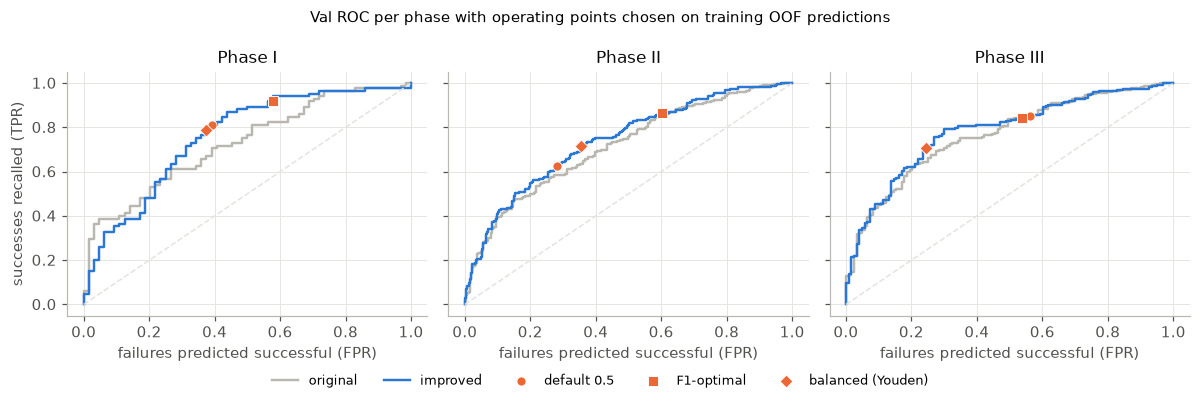

In [29]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
mk = {'default 0.5': 'o', 'F1-optimal': 's', 'balanced (Youden)': 'D'}
for i, ph in enumerate(PHASES):
    m = (val.phase == ph).values
    for p, c, lab in [(p_orig, GRAY, 'original'), (p_imp, BLUE, 'improved')]:
        fpr, tpr, _ = roc_curve(val.label.values[m], p[m]); ax[i].plot(fpr, tpr, color=c, lw=1.6, label=lab)
    for r, tt in THR.items():
        pp = p_imp[m] >= tt[ph]; yy = val.label.values[m]
        ax[i].scatter(((pp) & (yy == 0)).sum() / (yy == 0).sum(), ((pp) & (yy == 1)).sum() / (yy == 1).sum(), marker=mk[r], s=36, color=ORANGE, zorder=3,
                      label=f'{r}' if i == 0 else None, edgecolor='white', linewidth=.6)
    ax[i].plot([0, 1], [0, 1], color=GRID, lw=1, ls='--'); ax[i].set(title=f'Phase {ph}', xlabel='failures predicted successful (FPR)')
ax[0].set_ylabel('successes recalled (TPR)')
h_, l_ = ax[0].get_legend_handles_labels(); fig.legend(h_, l_, loc='lower center', ncol=5, fontsize=8.5, bbox_to_anchor=(.5, -.06))
fig.suptitle('Val ROC per phase with operating points chosen on training OOF predictions', fontsize=10)
plt.tight_layout(); plt.savefig('figures/p2_fig6_threshold_tradeoff.png', bbox_inches='tight'); plt.show()

**Takeaways (Section 9).**
* **The improvement is real for ranking, calibration and F1, but not for PR-AUC.**
  - Cross-fitted CV: the stack beats the original in **5/5 folds** on ROC-AUC (+0.029), PR-AUC (+0.024) and log loss (−0.018), and in 4/5 on F1 (+0.014).
  - Val paired bootstrap: ROC-AUC +0.024 [0.004, 0.045], log loss −0.020 [−0.034, −0.006] and F1 +0.023 [0.002, 0.043] all exclude 0. PR-AUC +0.009 [−0.015, 0.033] does not.
* **Phase I gains the most**, in CV ROC-AUC (0.645 → 0.696) and on val failures (53% → 39% predicted successful; Recruitment 55% → 27%). Recall on successes is unchanged (0.81), so this is a genuine gain, not a threshold shift.
  Pooling phases plus the design and history features transfers the recruitment signal from the much larger Phase II set.
* **Phase III ranking improves only slightly (CV 0.770 → 0.790), and its failure detection at 0.5 does not change (57% → 56%).**
  Efficacy and Other look slightly worse (60% → 70%), but n = 10 each, i.e. one trial, well inside the 95% CIs.
* **The threshold is where the Phase III trade-off lives** (figure above, thresholds chosen on training OOF only):
  - *Balanced (Youden)* thresholds cut Phase III's error on failures from **56% to 24%**: Recruitment 68% → 36%, Efficacy 70% → 40%, No recorded reason 54% → 21%.
    The cost is recall on successful Phase III trials, which falls from 0.85 to 0.71, with F1 0.795 → 0.773.
  - *F1-optimal* thresholds raise mean F1 from 0.737 to 0.752, but do it by predicting "success" more often (Phase II threshold 0.33). Phase II's failure error jumps from 28% to 60%.
  - **F1 rewards the majority class here.** Which operating point is "better" depends on whether a missed failure or a wrongly flagged success costs more, so F1 alone cannot tell you whether a model catches failing trials.
* **Category sizes and label noise limit every reason-level conclusion.** Only the All-failures, Recruitment (Phase II) and No-recorded-reason cells have n ≥ 50, and 86% of the reason labels are Part 1 predictions.

### Kaggle submission
Refit every base model on train + val, fit the stacker on 5-fold grouped OOF predictions of train + val, and predict test.

In [30]:
# Choose the year cap from the temporal holdout: the capped variant with the lowest holdout log loss.
caps = TEMP[TEMP.model.str.startswith('Stack + year trend')].set_index('model').LogLoss_mean
best_cap_name = caps.idxmin(); print('holdout log loss by cap:', caps.round(4).to_dict(), '\nchosen:', best_cap_name)
CAP_OFFSET = None if 'no cap' in best_cap_name else int(best_cap_name.split('+')[-1].strip(' )'))

TVFOLDS = []
for a, b in GroupKFold(5).split(TV, groups=TV.trial_id):
    fa, fb = TV.iloc[a].reset_index(drop=True), TV.iloc[b].reset_index(drop=True)
    TVFOLDS.append((a, b, fa, fb) + build_blocks(fa, fb))
P_TV_oof, P_TE = {}, {}
for k, f in BASE_FNS.items():
    P_TE[k] = f(BTV, TV, BTE, test.reset_index(drop=True)); P_TV_oof[k] = np.zeros(len(TV))
    for a, b, fa, fb, Bf, Ba in TVFOLDS: P_TV_oof[k][b] = f(Bf, fa, Ba, fb)
cap = None if CAP_OFFSET is None else int(TV.year.max()) + CAP_OFFSET
st_final = Stacker(list(BASES), year=True, cap=cap).fit(P_TV_oof, TV)
p_test = st_final.predict(P_TE, test.reset_index(drop=True))
print('year cap for test:', cap, '| stacker coef:', dict(zip(list(BASES) + [f'int_{p}' for p in PHASES] + [f'year_{p}' for p in PHASES], st_final.m.coef_[0].round(3))))
_, s_oof = summarize(TV, st_final.predict(P_TV_oof, TV), 'final OOF (train+val, in-sample stacker)'); print('train+val OOF:', {k: round(v, 3) for k, v in s_oof.items() if k != 'model'})
sub = pd.DataFrame({'ID': test.ID.values, 'label': np.clip(p_test, 0.02, 0.98)})
sub.to_csv('outputs/part2_submission.csv', index=False)
# Alternate (no year extrapolation) for comparison / as a fallback submission.
st_ny = Stacker(list(BASES), year=False).fit(P_TV_oof, TV)
pd.DataFrame({'ID': test.ID.values, 'label': np.clip(st_ny.predict(P_TE, test.reset_index(drop=True)), 0.02, 0.98)}).to_csv('outputs/part2_submission_alt_noyear.csv', index=False)
print('mean predicted P(success) on test by phase:', sub.groupby(test.phase.values).label.mean().round(3).to_dict())
print('train+val success rate by phase:         ', TV.groupby('phase').label.mean().round(3).to_dict())
sub.head()

holdout log loss by cap: {'Stack + year trend, no cap': 0.5593, 'Stack + year trend, cap = last year (+0)': 0.5583, 'Stack + year trend, cap = +1': 0.5591, 'Stack + year trend, cap = +2': 0.5594, 'Stack + year trend, cap = +3': 0.5594} 
chosen: Stack + year trend, cap = last year (+0)


year cap for test: 2013 | stacker coef: {'lr_phase': np.float64(0.176), 'lr_pool': np.float64(0.341), 'hgb': np.float64(0.46), 'mnb': np.float64(-0.002), 'knn': np.float64(0.09), 'int_I': np.float64(0.033), 'int_II': np.float64(-0.004), 'int_III': np.float64(-0.075), 'year_I': np.float64(0.082), 'year_II': np.float64(0.016), 'year_III': np.float64(0.298)}
train+val OOF: {'F1_mean': 0.724, 'ROC_AUC_mean': 0.744, 'PR_AUC_mean': 0.777, 'LogLoss_mean': 0.579}
mean predicted P(success) on test by phase: {'I': 0.614, 'II': 0.549, 'III': 0.758}
train+val success rate by phase:          {'I': 0.567, 'II': 0.476, 'III': 0.654}


,ID,label
0,TR11252_III,0.707083
1,TR08672_II,0.387530
2,TR07815_I,0.628002
3,TR08013_I,0.515633
4,TR05100_II,0.537334


## 10. Results summary

In [31]:
summary = pd.DataFrame(RESULTS).drop_duplicates('model', keep='last')
summary.round(4).to_csv('outputs/p2_results_summary.csv', index=False)
pd.concat(PHASE_ROWS).drop_duplicates(['model', 'phase'], keep='last').round(4).to_csv('outputs/p2_results_by_phase.csv', index=False)
TEMP.round(4).to_csv('outputs/p2_temporal_holdout.csv', index=False)
pd.Series(adv).round(4).to_csv('outputs/p2_adversarial_auc.csv')
pi.round(5).to_csv('outputs/p2_adversarial_importance.csv')
summary[['group', 'model', 'F1_mean', 'ROC_AUC_mean', 'PR_AUC_mean', 'LogLoss_mean', 'cv_auc', 'cv_auc_sd', 'cv_ll']].round(3)

,group,model,F1_mean,ROC_AUC_mean,PR_AUC_mean,LogLoss_mean,cv_auc,cv_auc_sd,cv_ll
0,A,"LR per-phase, TF-IDF 1-2g, C=0.1",0.718,0.731,0.787,0.602,0.701,0.021,0.616
1,A,"LR per-phase, TF-IDF 1-2g, C=0.3",0.714,0.736,0.786,0.589,0.709,0.018,0.604
2,A,"LR per-phase, TF-IDF 1-2g, C=1",0.709,0.731,0.776,0.593,0.711,0.015,0.605
3,A,"LR per-phase, TF-IDF 1-2g, C=3",0.715,0.718,0.763,0.623,0.707,0.012,0.632
4,A,"LR per-phase, TF-IDF unigram, C=0.3",0.711,0.740,0.787,0.586,0.710,0.017,0.603
5,A,"Multinomial NB per-phase, BoW, alpha=0.1",0.684,0.681,0.697,3.723,0.683,0.015,3.749
6,A,"Multinomial NB per-phase, BoW, alpha=1.0",0.695,0.689,0.706,3.620,0.684,0.014,3.630
7,A,"kNN per-phase, TF-IDF cosine, k=15",0.687,0.703,0.751,0.646,0.689,0.024,0.668
8,A,"kNN per-phase, TF-IDF cosine, k=50",0.703,0.709,0.760,0.609,0.692,0.020,0.624
9,A,"kNN per-phase, TF-IDF cosine, k=100",0.715,0.716,0.770,0.611,0.688,0.017,0.628
